# 객체탐지-1 · 박스 · IoU · NMS · 채점

**한 줄 요약** · 사진 속 "무엇이 · 어디에"를 박스 숫자로 적고, IoU → NMS → 짝짓기 → AP 순서로 채점하는 법을 손계산하고 라이브러리 값과 맞춰 봄

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 탐지 모델 출력(boxes · scores · labels)과 정답 XML · target 딕셔너리의 모양 · 자료형을 말한다
2. xyxy · xywh · cxcywh를 서로 바꾸고, 크기 바꾸기 · 좌우 뒤집기 뒤의 박스를 손으로 계산한다
3. IoU를 손계산해 `box_iou`와 맞추고, NMS가 남기는 박스를 미리 말한다
4. 신뢰도 순 짝짓기로 TP · FP · FN을 정하고 정밀도 · 재현율 · F1을 계산한다
5. PR 점 → 포락선 → AP · mAP를 직접 계산해 torchmetrics 값과 소수 넷째 자리까지 맞춘다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">라벨링 도구 · 데이터셋마다 박스 숫자 형식이 다를 때</td>
<td style="text-align: left;">xyxy · xywh · cxcywh 바꾸기 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">증강(뒤집기 · 크기 바꾸기) 후 박스가 어긋날 때</td>
<td style="text-align: left;">사진과 박스를 함께 바꾸기 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">결과 사진에 같은 물체 박스가 여러 개 겹칠 때</td>
<td style="text-align: left;">신뢰도 임곗값 · NMS 기준 (4장)</td>
</tr>
<tr>
<td style="text-align: left;">학습한 탐지 모델의 점수를 보고 · 비교할 때</td>
<td style="text-align: left;">AP50 · AP@[.5:.95] · mAP 읽기 (6 · 7장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/od1_map.png" alt="객체탐지-1 학습 지도" width="761">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (사전학습 SSD로 예측만 하므로 GPU가 없어도 몇 분 안에 끝남)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 실행 장치 · 데이터 · 그림 도우미</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">분류 vs 탐지</td>
<td style="text-align: left;">분류 모델로는 왜 위치를 못 찾고, 탐지 모델은 무엇을 내놓는가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">박스 숫자 · XML</td>
<td style="text-align: left;">박스 네 숫자의 뜻과 정답 XML은? 크기 · 뒤집기 때 박스는?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">IoU</td>
<td style="text-align: left;">예측 박스가 정답과 얼마나 맞았는지 숫자 하나로 어떻게 재는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">신뢰도 · NMS</td>
<td style="text-align: left;">수백 개의 후보를 점수로 거르고, 겹친 중복을 어떻게 지우는가?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">짝짓기 채점</td>
<td style="text-align: left;">TP · FP · FN은 어떻게 정하고, 정밀도 · 재현율은 무엇을 재는가?</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">AP · mAP</td>
<td style="text-align: left;">모든 기준을 묶은 AP · mAP는 어떻게 계산하고 어떻게 읽는가?</td>
</tr>
<tr>
<td style="text-align: center;">7</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">사전학습 모델의 예측을 직접 채점한 AP와 라이브러리 AP가 같은가?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

### 객체탐지 3권 · 핵심 기준

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">권</th>
<th style="text-align: left;">핵심 질문</th>
<th style="text-align: left;">핵심 숫자</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><strong>1</strong> 박스 · IoU · NMS · 채점 (이 권)</td>
<td style="text-align: left;">맞았는지 어떻게 채점하나?</td>
<td style="text-align: left;">IoU · AP50 · mAP</td>
</tr>
<tr>
<td style="text-align: left;">2 학습 · 평가 · 오류분석</td>
<td style="text-align: left;">내 클래스로 어떻게 학습 · 평가하나?</td>
<td style="text-align: left;">학습 손실 · 검증 mAP</td>
</tr>
<tr>
<td style="text-align: left;">3 모델 비교 · YOLO 실전</td>
<td style="text-align: left;">프로젝트에서는 무엇을 쓰나?</td>
<td style="text-align: left;">mAP · 속도 · 파라미터 수</td>
</tr>
</tbody>
</table>

- 권마다 묻는 질문 · 재료 전체 표는 부록 "이 노트북을 만든 방법"

---
## 0. 준비

모든 장에서 쓰는 라이브러리 · 설정 · 데이터 경로 · 그림 도우미를 한 번에 준비함. **셀은 위에서부터 차례로 실행**(앞 섹션의 변수를 이어서 씀).

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">설정</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이유</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>KMP_DUPLICATE_LIB_OK</code></td>
<td style="text-align: left;">OpenMP 중복 허용</td>
<td style="text-align: left;">Windows Anaconda에서 numpy(MKL)와 torch가 OpenMP를 따로 불러 커널이 죽는 문제 방지</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.manual_seed(0)</code> · <code>cudnn.deterministic</code></td>
<td style="text-align: left;">난수 · cuDNN 연산 고정</td>
<td style="text-align: left;">다시 실행해도 같은 결과 (7장 사진 고르기는 <code>np.random.default_rng(0)</code>)</td>
</tr>
<tr>
<td style="text-align: left;"><code>device</code></td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code></td>
<td style="text-align: left;">GPU 없는 PC에서도 코드 수정 없이 실행 (CPU로도 실행해 확인: NMS 전 후보 수만 신뢰도 0.01 경계에서 1개 차이, AP 등 나머지 값은 같음)</td>
</tr>
<tr>
<td style="text-align: left;"><code>kagglehub.dataset_download</code></td>
<td style="text-align: left;">Oxford-IIIT Pet 받기 · 캐시 경로</td>
<td style="text-align: left;">처음 한 번만 내려받고(약 0.8GB) 이후에는 경로만 돌려줌</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">데이터 · 모델</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">처음 나오는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>IMAGES</code> · <code>XMLS</code> · <code>ANN</code></td>
<td style="text-align: left;">사진 7,390장 · 머리 박스 XML 3,686개 · 목록 txt</td>
<td style="text-align: left;">1-1 · 2-1 · 2-4</td>
</tr>
<tr>
<td style="text-align: left;"><code>classifier</code></td>
<td style="text-align: left;">ImageNet 사전학습 ResNet18 (분류)</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>detector</code></td>
<td style="text-align: left;">COCO 사전학습 SSD300 (탐지) · 처음 실행 때 weights 자동 다운로드</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>GT</code> · <code>PRED_A</code> · <code>PRED_B</code></td>
<td style="text-align: left;">손으로 검산할 수 있는 정답 3개 · 예측 6개 · 4개</td>
<td style="text-align: left;">5-1 · 5-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>photos</code> · <code>gt_all</code></td>
<td style="text-align: left;">채점용 사진 24장 · 클래스별 정답</td>
<td style="text-align: left;">7장</td>
</tr>
</tbody>
</table>

**도우미 함수** · `load_image(이름)` 사진 열기 · `draw_box(ax, 박스, 색)` 박스 하나 그리기 · `show(사진, gt=, pred=, cand=)` 사진 위에 정답 · 예측 · 후보 박스

In [1]:
# 라이브러리 불러오기
import copy                         # 모델 복사 (4-3)
import os                           # 환경 변수
import xml.etree.ElementTree as ET  # XML 정답 파일 읽기 (2-1)
from collections import Counter     # 개수 세기 (2-4)
from pathlib import Path            # 폴더 · 파일 경로

import kagglehub                 # Kaggle 데이터 받기 (있으면 경로만)
import matplotlib.pyplot as plt  # 사진 · 그래프
import numpy as np               # 배열 계산 (6장 AP)
import torch                     # 텐서 · 모델 실행
import torchvision               # 사전학습 모델 · 박스 함수
from matplotlib import patches   # 사각형 도형 = 박스 그리기
from PIL import Image            # 사진 파일 열기


# Windows Anaconda: numpy(MKL) · torch가 OpenMP를 따로 불러 생기는 충돌 방지
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # 커널이 OpenMP 충돌로 죽지 않게


# seed 고정 + cuDNN 결정적 연산 → 다시 실행해도 같은 결과
torch.manual_seed(0)                       # 난수 기준값 고정 → 매번 같은 결과
torch.backends.cudnn.deterministic = True  # GPU 연산도 매번 같은 값
torch.backends.cudnn.benchmark = False     # 실행마다 계산 방법이 바뀌지 않게


# 실행 장치: GPU가 있으면 cuda, 없으면 cpu (코드는 그대로)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
plt.rcParams["font.family"] = "Malgun Gothic"                          # 그림 속 한글 (Windows)
plt.rcParams["axes.unicode_minus"] = False                             # 음수 기호 깨짐 방지


# Oxford-IIIT Pet: 처음이면 내려받고(약 0.8GB), 있으면 캐시 경로
ROOT = Path(kagglehub.dataset_download(                     # 캐시에 있으면 경로만 받음
    "zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1"))
IMAGES = ROOT / "images" / "images"                         # 사진 폴더
ANN = ROOT / "annotations" / "annotations"                  # 목록 txt · xmls 폴더
XMLS = ANN / "xmls"                                         # 머리 박스 정답 XML
print("torch", torch.__version__.split("+")[0],             # 설치된 버전 기록
      "| torchvision", torchvision.__version__.split("+")[0])
print("실행 장치:", device.type)                            # cuda인지 cpu인지 확인
print("사진", len(list(IMAGES.glob("*.jpg"))), "장 | XML",  # 받은 파일 수 확인
      len(list(XMLS.glob("*.xml"))), "개")

torch 2.11.0 | torchvision 0.26.0
실행 장치: cuda
사진 7390 장 | XML 3686 개


In [2]:
# 그림 도우미: 정답 = 초록 실선 · 예측 = 파랑 실선 · 후보 = 파랑 점선
GT_COLOR, PRED_COLOR, BAD_COLOR = "#2e7d32", "#0277bd", "#c62828"  # 정답 · 예측 · 잘못된 박스 색


def load_image(stem):                                         # 이름만 주면 사진을 엶
    """파일 이름(확장자 없이) → RGB 사진"""                   # 함수 설명
    return Image.open(IMAGES / f"{stem}.jpg").convert("RGB")  # 흑백 사진도 3채널로 맞춤


def draw_box(ax, box, color, ls="-", lw=2.5, text=None):  # xyxy 박스 하나 그리기
    x1, y1, x2, y2 = [float(v) for v in box]              # 텐서여도 숫자로 꺼냄
    ax.add_patch(patches.Rectangle(                       # (왼쪽 위 점, 너비, 높이)
        (x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, ls=ls, lw=lw))
    if text:                                              # 이름표가 있을 때만
        ax.text(x1 + 3, y1 + 3, text, va="top", fontsize=9, color="white",  # 박스 왼쪽 위에 글자
                bbox=dict(fc=color, ec="none", pad=1))


def show(img, gt=(), pred=(), cand=(), labels=None, title="", ax=None):  # 사진 + 박스 세 종류
    """사진 위에 후보 · 예측 · 정답 박스"""         # 함수 설명
    if ax is None:                                  # 그릴 칸을 안 주면
        _, ax = plt.subplots(figsize=(5, 4))        # 새 그림 하나
    ax.imshow(img)                                  # 사진 깔기
    ax.axis("off")                                  # 눈금 숨김
    for b in cand:                                  # 후보 = 점선
        draw_box(ax, b, PRED_COLOR, ls="--", lw=1)  # 가늘게 → 정답이 가려지지 않게
    for i, b in enumerate(pred):                    # 예측 = 실선
        draw_box(ax, b, PRED_COLOR, text=labels[i] if labels else None)  # 이름표는 있으면만
    for b in gt:                                    # 정답 = 초록
        draw_box(ax, b, GT_COLOR, lw=3)             # 가장 굵게 → 맨 위에 보이게
    ax.set_title(title, fontsize=10)                # 그림 제목
    return ax                                       # 바깥에서 더 그릴 수 있게

---
## 1. 분류 vs 탐지

> **이 장의 흐름**
>
> - 10 이미지분류에서는 사진 한 장 → 클래스 하나였다 → 여러 물체의 "무엇 · 어디에"를 답하려면 탐지 모델이 필요.
> - 탐지 모델이 내놓는 출력의 모양부터 확인

**파이프라인 위치** · ④ 모델 — 분류 출력(확률 하나) vs 탐지 출력(boxes · scores · labels)

### 1-1. `A` 분류 모델의 한계 · `resnet18()` · `topk()` <sub>Day01 D1-1</sub>

> 🎯 **분류 모델에 개와 사람이 함께 있는 사진을 넣으면 무엇을 알려 주고, 무엇을 알려 주지 못하는가?**

💡 **쉽게 말하면**

- 분류 모델은 **사진 전체에 이름표 하나를 붙이는 사람**.
- 무엇이 있는지는 말해도, 어디에 · 몇 개 있는지는 답할 칸이 없음.

**실행 흐름**

1. 개 + 사람 사진
2. ResNet18
3. 1000칸 확률
4. 상위 3개
5. 'person' 이름 확인
6. 창문을 옮겨 가며 분류할 때의 횟수

**먼저 예측** · 1000칸 확률의 합은 얼마이고, 사람은 상위 3개에 나올까? — 답은 코드 실행 결과 아래에

In [3]:
from torchvision.models import ResNet18_Weights, resnet18  # 분류 모델 · 사전학습 가중치

# ImageNet 1000개 이름으로 학습된 분류 모델
cls_w = ResNet18_Weights.IMAGENET1K_V1                  # ImageNet 1000칸 가중치
classifier = resnet18(weights=cls_w).eval().to(device)  # 평가 모드로 장치에 올림
pair = load_image("great_pyrenees_126")                 # 개 + 사람이 함께 있는 사진


# 사진 한 장 → 1000칸 확률 → 상위 3개
x = cls_w.transforms()(pair).unsqueeze(0).to(device)       # (1, 3, 224, 224)
with torch.no_grad():                                      # 기울기 기록 안 함 (예측만)
    prob = classifier(x).softmax(dim=1)[0]                 # (1, 1000) → [0] → (1000,)
print("출력 모양:", tuple(prob.shape),                     # 1000칸 하나뿐 = 위치 없음
      "| 확률 합:", round(prob.sum().item(), 3))
for p, i in zip(*prob.topk(3)):                            # topk → (값들, 위치들)
    print(f"  {cls_w.meta['categories'][i]:15s} {p:.3f}")  # 번호 → 이름 · 확률
print("'person'이 1000개 이름에 있나?",                    # 사람 칸이 있는지
      "person" in cls_w.meta["categories"])


# 위치까지 알려면? 창문을 옮겨 가며 잘라서 분류 → 창문 수 세기
W, H = pair.size                                                       # PIL은 (가로, 세로)
n_win = 0                                                              # 창문 수를 셀 변수
for size in (64, 128, 256):                                            # 창문 크기 3가지
    for ratio in (0.5, 1, 2):                                          # 모양 3가지 (세로 ÷ 가로)
        w, h = int(size / ratio ** 0.5), int(size * ratio ** 0.5)      # 넓이는 같게 · 모양만 바꿈
        n_win += ((W - w) // 16 + 1) * ((H - h) // 16 + 1)             # 16픽셀씩 이동
print("사진", pair.size, "→ 창문", n_win, "개 = 분류를", n_win, "번")  # 분류를 몇 번 돌려야 하나

출력 모양: (1000,) | 확률 합: 1.0
  Great Pyrenees  0.957
  Samoyed         0.025
  kuvasz          0.013
'person'이 1000개 이름에 있나? False
사진 (500, 375) → 창문 2975 개 = 분류를 2975 번


**결과** · 예측 정답은 `1.0` — softmax라 합이 1, 사람은 ImageNet 1000개 이름에 아예 없어 나올 수 없음

- `출력 모양: (1000,) | 확률 합: 1.0` — 사진 한 장 → 1000칸 확률 하나 (위치 정보 없음)
- `Great Pyrenees  0.957` — 개 품종 하나에 확률 대부분 → 함께 있는 사람은 답에 없음
- `'person'이 1000개 이름에 있나? False` — 학습한 이름표에 없는 물체는 답할 수 없음
- `사진 (500, 375) → 창문 2975 개 = 분류를 2975 번` — 창문 크기 3가지 × 모양 3가지를 16픽셀씩 옮기면 사진 한 장에 분류 2975번 → 너무 느림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 (ResNet18)</td>
<td style="text-align: left;">사진 → 클래스 확률 <strong>하나</strong> (위치 없음)</td>
<td style="text-align: left;">사진에 주인공이 하나 · 위치가 필요 없을 때</td>
</tr>
<tr>
<td style="text-align: left;">창문 옮기기 + 분류</td>
<td style="text-align: left;">창문마다 분류 → 위치는 알지만 수천 번 계산</td>
<td style="text-align: left;">원리 이해용 (느려서 실제로는 안 씀)</td>
</tr>
<tr>
<td style="text-align: left;">탐지 (SSD · Faster R-CNN · YOLO)</td>
<td style="text-align: left;">사진 → 박스 여러 개 + 클래스 + 신뢰도, 한 번 실행</td>
<td style="text-align: left;">여러 물체의 위치 · 개수가 필요할 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 분류 확률은 "사진 전체가 이 이름일 확률"이지 물체 개수나 위치가 아님 → 여러 물체 사진에 쓰면 하나만 답함

> ✅ **한 줄 정리** · 분류는 사진 한 장에 이름 하나를 답하므로, 여러 물체의 위치까지 알려면 탐지 모델이 필요하다.

**딥러닝 코드에서는**

- 분류는 `logits.argmax(dim=1)` (사진마다 숫자 하나), 탐지는 `model(images)[i]["boxes"]` (사진마다 박스 N개)

### 1-2. `A` 탐지 모델의 출력 세 가지 · `ssd300_vgg16()` · `model([x])` <sub>Day01 D1-2</sub>

> 🎯 **탐지 모델은 사진 한 장에 대해 무엇을 몇 줄 내놓는가?**

💡 **쉽게 말하면**

- 탐지 모델은 **사진 위에 포스트잇을 붙이는 사람**.
- 포스트잇마다 위치(박스) · 이름(라벨) · 확신(점수)을 적는데, 확신이 낮은 것까지 일단 많이 붙임.

<img src="images/od1_cls_vs_det.png" alt="분류는 이름 하나, 탐지는 박스마다 세 가지" width="763">

**실행 흐름**

1. COCO로 학습된 SSD300 불러오기
2. 사진을 0~1 텐서로 · `model([x])`
3. boxes · scores · labels 모양
4. 신뢰도 0.5로 거르기 · 그림

**먼저 예측** · 고양이 한 마리 사진인데, 모델이 낸 박스는 몇 줄일까? — 답은 코드 실행 결과 아래에

COCO 이름 수: 91 | cat 번호: 17 | dog 번호: 18


boxes  모양 (200, 4)
scores 모양 (200,)
labels 모양 (200,)
  cat   0.996 [40, 29, 358, 247]
  bed   0.098 [46, 136, 387, 251]
  sheep 0.077 [293, 115, 351, 136]
신뢰도 > 0.5: 1 / 200 줄


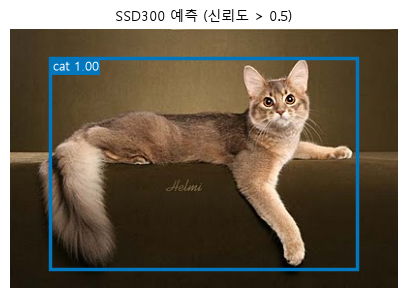

In [4]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # 탐지 모델

# COCO(배경 포함 91칸)로 학습된 탐지 모델 SSD300
det_w = SSD300_VGG16_Weights.COCO_V1                                 # COCO 91칸 가중치
detector = ssd300_vgg16(weights=det_w).eval().to(device)             # 처음엔 weights 자동 다운로드
COCO = det_w.meta["categories"]                                      # 0번 = '__background__' (배경)
print("COCO 이름 수:", len(COCO), "| cat 번호:", COCO.index("cat"),  # 7장에서 번호 바꿀 때 씀
      "| dog 번호:", COCO.index("dog"))


# 탐지 실행 도우미: 사진 목록을 넣고 → 사진마다 dict 하나
def run(model, img):                             # 사진 한 장 → 예측 dict
    x = det_w.transforms()(img).to(device)       # PIL → 0~1 텐서 (크기 그대로)
    with torch.no_grad():                        # 예측만 · 메모리 절약
        out = model([x])[0]                      # [사진] → [dict] → [0]
    return {k: v.cpu() for k, v in out.items()}  # CPU로 옮겨야 그림 · 계산이 편함


# 고양이 한 마리 사진 → 박스 몇 개?
cat_img = load_image("Abyssinian_173")                                   # 고양이 한 마리 사진
out = run(detector, cat_img)                                             # boxes · scores · labels
for k, v in out.items():                                                 # 세 가지 출력마다
    print(f"{k:6s} 모양 {tuple(v.shape)}")                               # 줄 수 N이 같은지
# 같은 위치 = 박스 하나
for b, lab, s in zip(out["boxes"][:3], out["labels"][:3], out["scores"][:3]):
    print(f"  {COCO[lab]:5s} {s:.3f} {[round(v) for v in b.tolist()]}")  # 이름 · 점수 · 박스
keep = out["scores"] > 0.5                                               # 신뢰도 0.5 넘는 줄만
print("신뢰도 > 0.5:", keep.sum().item(), "/", len(keep), "줄")          # 남는 줄 수


# 신뢰도 0.5 넘는 박스 그리기
show(cat_img, pred=out["boxes"][keep],  # 남은 박스만 그림
     labels=[f"{COCO[lab]} {s:.2f}" for lab, s
             in zip(out["labels"][keep], out["scores"][keep])],
     title="SSD300 예측 (신뢰도 > 0.5)")
plt.show()                              # 그림 출력

**결과** · 예측 정답은 `200`줄 — 그중 신뢰도 0.5를 넘는 줄은 `1`줄뿐 (낮은 점수 후보까지 최대 200개를 냄)

- `COCO 이름 수: 91 | cat 번호: 17 | dog 번호: 18` — COCO 80종 + 빈 번호 + 0번 배경 = 91칸, cat · dog 번호는 7장에서 우리 번호로 바꿀 때 씀
- `boxes  모양 (200, 4)` — 박스 200개 × 숫자 4개 (xyxy, 2장)
- `scores 모양 (200,)` — 박스마다 신뢰도 하나, 높은 순으로 정렬
- `cat   0.996 [40, 29, 358, 247]` — 1등 = 고양이 0.996, 박스는 사진 대부분 (몸 전체)
- `bed   0.098 [46, 136, 387, 251]` — 2등부터는 침대 · 양처럼 낮은 점수 후보
- `신뢰도 > 0.5: 1 / 200 줄` — 기준값이 결과 개수를 정함 (4장)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>boxes</code> [N, 4]</td>
<td style="text-align: left;">박스 위치 (xmin, ymin, xmax, ymax), 원본 사진 픽셀 기준</td>
<td style="text-align: left;">그림 그리기 · IoU 계산</td>
</tr>
<tr>
<td style="text-align: left;"><code>scores</code> [N]</td>
<td style="text-align: left;">박스마다 신뢰도 0~1, 높은 순으로 정렬</td>
<td style="text-align: left;">기준값으로 거르기 · AP 계산 순서</td>
</tr>
<tr>
<td style="text-align: left;"><code>labels</code> [N]</td>
<td style="text-align: left;">클래스 번호 (0 = 배경은 안 나옴)</td>
<td style="text-align: left;"><code>COCO[번호]</code>로 이름 찾기</td>
</tr>
<tr>
<td style="text-align: left;">분류 출력 [1000]</td>
<td style="text-align: left;">사진 하나에 확률 벡터 하나 (길이 고정)</td>
<td style="text-align: left;">비교: 탐지는 줄 수 N이 사진마다 다름</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 탐지 모델에는 사진 **목록**을 넣고 사진마다 dict를 돌려받음 → 한 장이어도 `model([x])[0]` (분류처럼 `model(x)`로 넣으면 에러)

> ✅ **한 줄 정리** · 탐지 모델은 사진마다 boxes · scores · labels 세 텐서를 같은 순서로 내놓고, 신뢰도 기준으로 걸러서 쓴다.

**딥러닝 코드에서는**

- `for b, s, lab in zip(out["boxes"], out["scores"], out["labels"])` — 세 텐서의 같은 위치가 박스 하나

---
## 2. 박스 숫자 · XML

> **이 장의 흐름**
>
> - 1장에서 모델이 박스 숫자 네 개를 냈다 → 그 숫자의 뜻과 정답 파일(XML)을 같은 약속으로 읽어야 예측과 정답을 비교할 수 있음.
> - 크기 · 뒤집기 때 박스를 바꾸는 법과 모델이 받는 한 샘플의 형식까지

**파이프라인 위치** · ① 데이터 준비 · ③ 전처리 — 정답 읽기 · 박스 변환 · 데이터 점검 · target 만들기

### 2-1. `A` XML 정답 읽기 · `ET.parse()` · `findtext()` · `iter()` <sub>Day01 D1-0 · D1-3</sub>

> 🎯 **XML 정답 파일에서 사진 크기 · 이름 · 박스를 어떻게 꺼내는가?**

💡 **쉽게 말하면**

- XML은 **태그로 칸을 나눈 정답지**.
- `<object>` 하나가 물체 하나이고, 그 안의 `<bndbox>`에 박스 네 숫자가 적힘.

**실행 흐름**

1. `ET.parse` · `getroot`
2. `findtext`(파일 이름 · 크기)
3. `iter("object")`로 물체마다
4. bndbox 네 숫자
5. 함수 `read_voc`로 묶기
6. 사진 3장 그림

**먼저 예측** · Abyssinian_173.xml의 박스 네 숫자와 이름은? — 답은 코드 실행 결과 아래에

filename: Abyssinian_173.jpg
size    : 400 × 267
name    : cat | bndbox: [241, 31, 310, 102]
read_voc: [[241.0, 31.0, 310.0, 102.0]] ['cat']


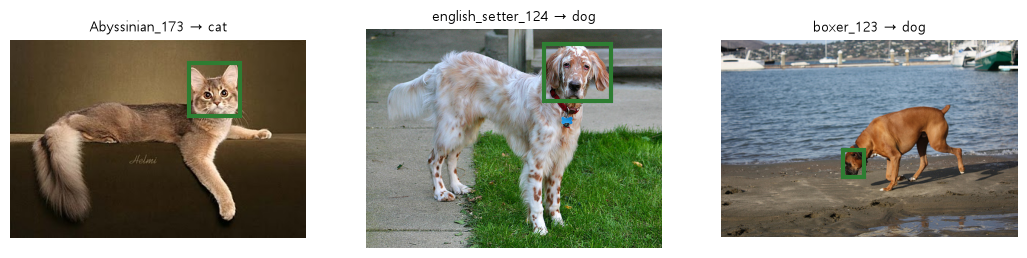

In [5]:
# XML 한 개 = 사진 한 장의 정답
root = ET.parse(XMLS / "Abyssinian_173.xml").getroot()     # XML 파일 → 맨 위 태그
print("filename:", root.findtext("filename"))              # 짝이 되는 사진 이름
print("size    :", root.findtext("size/width"), "×",       # 경로로 안쪽 태그 글자
      root.findtext("size/height"))
for obj in root.iter("object"):                            # 물체 하나 = <object> 하나
    bb = obj.find("bndbox")                                # 박스 네 숫자가 든 태그
    print("name    :", obj.findtext("name"), "| bndbox:",  # 이름 · 박스
          [int(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])


# 위 과정을 함수로: 파일 이름 → (박스 목록, 이름 목록)
def read_voc(stem):                                  # 위 과정을 함수로
    root = ET.parse(XMLS / f"{stem}.xml").getroot()  # 사진 이름 → XML
    boxes, names = [], []                            # 물체마다 쌓을 목록
    for obj in root.iter("object"):                  # 물체가 여러 개여도 모두
        bb = obj.find("bndbox")                      # 박스 네 숫자가 든 태그
        boxes.append([float(bb.findtext(k))          # 글자 → 실수 (계산하려면 필수)
                      for k in ("xmin", "ymin", "xmax", "ymax")])
        names.append(obj.findtext("name"))           # cat · dog
    return boxes, names                              # 박스 목록 · 이름 목록


# 사진 3장 + XML 정답 박스 (정답 = 머리)
boxes, names = read_voc("Abyssinian_173")                                   # 함수로 다시 읽기
print("read_voc:", boxes, names)                                            # 직접 읽은 값과 같은지
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))                           # 사진 3장 나란히
for stem, ax in zip(["Abyssinian_173", "english_setter_124", "boxer_123"],  # 사진 · 칸 짝짓기
                    axes):
    b, n = read_voc(stem)                                                   # 그 사진의 정답
    show(load_image(stem), gt=b, title=f"{stem} → {n[0]}", ax=ax)           # 정답 = 초록
plt.show()                                                                  # 그림 출력

**결과** · 예측 정답은 `[241, 31, 310, 102]` · `cat` — 이 데이터의 정답은 몸 전체가 아니라 **머리**(얼굴) 박스

- `filename: Abyssinian_173.jpg` — `<filename>` → 짝이 되는 사진 파일
- `size    : 400 × 267` — `<size>` 안 너비 × 높이 (픽셀)
- `name    : cat | bndbox: [241, 31, 310, 102]` — `<object>` 안 이름 · 박스 (xmin, ymin, xmax, ymax)
- `read_voc: [[241.0, 31.0, 310.0, 102.0]] ['cat']` — 박스 목록 · 이름 목록 → 물체가 여러 개여도 같은 모양

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>root.findtext("size/width")</code></td>
<td style="text-align: left;">경로의 첫 태그 글자 하나</td>
<td style="text-align: left;">사진마다 하나뿐인 값 (파일 이름 · 크기)</td>
</tr>
<tr>
<td style="text-align: left;"><code>root.iter("object")</code></td>
<td style="text-align: left;">같은 이름 태그를 모두 돌기</td>
<td style="text-align: left;">물체가 여러 개일 수 있는 값 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;"><code>root.find("object/bndbox")</code></td>
<td style="text-align: left;">첫 번째 하나만</td>
<td style="text-align: left;">물체가 반드시 하나일 때만 (Bengal_105처럼 2개면 하나를 놓침)</td>
</tr>
<tr>
<td style="text-align: left;">VOC XML vs COCO JSON</td>
<td style="text-align: left;">사진마다 파일 하나 vs 데이터 전체가 파일 하나</td>
<td style="text-align: left;">형식 변환 비교는 객체탐지-3</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `findtext`는 문자열을 돌려줌 → 계산 전에 `float()` · `int()` 변환 필수 (`"310" - "241"`은 에러)

> ✅ **한 줄 정리** · XML은 `ET.parse`로 읽고, 물체마다 `<object>`의 `name`과 `bndbox` 네 숫자를 꺼낸다.

**딥러닝 코드에서는**

- 탐지 `Dataset.__getitem__` 안에서 `read_voc(stem)` → target 딕셔너리 (2-5, 객체탐지-2)

### 2-2. `A` 박스 표기 세 가지 · `box_convert()` · `crop()` <sub>Day01 D1-3</sub>

> 🎯 **같은 박스를 숫자 네 개로 적는 방법은 몇 가지이고, 잘못 읽으면 어떻게 되는가?**

💡 **쉽게 말하면**

- 박스 표기는 **주소 적는 방식**.
- 두 모서리(xyxy) · 모서리 + 크기(xywh) · 가운데 + 크기(cxcywh) 모두 같은 집을 가리키지만, 형식을 섞어 읽으면 엉뚱한 집이 됨.

<img src="images/od1_box_formats.png" alt="같은 박스를 적는 세 가지 표기" width="638">

**실행 흐름**

1. xyxy 박스
2. `box_convert`로 xywh · cxcywh
3. 뒤 두 숫자를 너비 · 높이로 잘못 읽기
4. PIL `crop` vs 배열 슬라이싱 · 그림

**먼저 예측** · xyxy `[241, 31, 310, 102]`를 xywh로 바꾸면 너비 · 높이는? — 답은 코드 실행 결과 아래에

xyxy  : [[241.0, 31.0, 310.0, 102.0]]
xywh  : [[241.0, 31.0, 69.0, 71.0]]
cxcywh: [[275.5, 66.5, 69.0, 71.0]]
잘못 읽은 박스: [241.0, 31.0, 551.0, 133.0] | 사진 너비: 400
crop (가로, 세로): (69, 71) | 배열 조각: (71, 69, 3)


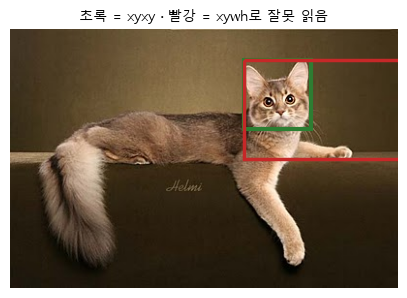

In [6]:
from torchvision.ops import box_convert  # 표기 바꾸는 함수

# 같은 박스 · 세 가지 표기
b = torch.tensor(boxes)                                      # [[241, 31, 310, 102]] = xyxy
print("xyxy  :", b.tolist())                                 # 원래 = 두 모서리
print("xywh  :", box_convert(b, "xyxy", "xywh").tolist())    # 왼쪽 위 + 크기
print("cxcywh:", box_convert(b, "xyxy", "cxcywh").tolist())  # 가운데 + 크기


# 뒤 두 숫자를 너비 · 높이로 잘못 읽으면
x1, y1, x2, y2 = boxes[0]                                         # 첫 박스 네 숫자
wrong = [x1, y1, x1 + x2, y1 + y2]                                # 310, 102를 너비 · 높이로 읽음
print("잘못 읽은 박스:", wrong, "| 사진 너비:", cat_img.size[0])  # 사진 밖으로 나가는지


# 박스로 얼굴 자르기: PIL은 (x, y), 배열은 [y, x]
x1, y1, x2, y2 = [int(v) for v in boxes[0]]  # 자를 때는 정수
face = cat_img.crop((x1, y1, x2, y2))        # crop = (왼, 위, 오른, 아래) = xyxy
arr = np.array(cat_img)                      # (세로, 가로, 채널)
print("crop (가로, 세로):", face.size,       # PIL = (가로, 세로)
      "| 배열 조각:", arr[y1:y2, x1:x2].shape)


# 정답(초록) vs 잘못 읽은 박스(빨강)
ax = show(cat_img, gt=boxes, title="초록 = xyxy · 빨강 = xywh로 잘못 읽음")  # 정답 먼저
draw_box(ax, wrong, BAD_COLOR)  # 잘못 읽은 박스 겹쳐 그림
plt.show()                      # 그림 출력

**결과** · 예측 정답은 `69` · `71` (310 - 241 = 69, 102 - 31 = 71)

- `xywh  : [[241.0, 31.0, 69.0, 71.0]]` — 왼쪽 위 (241, 31) + 너비 69 · 높이 71
- `cxcywh: [[275.5, 66.5, 69.0, 71.0]]` — 가운데 x = 241 + 69 ÷ 2 = 275.5, y = 31 + 71 ÷ 2 = 66.5
- `잘못 읽은 박스: [241.0, 31.0, 551.0, 133.0] | 사진 너비: 400` — 310을 너비로 읽어 241 + 310 = 551 → 사진 밖으로 나감 (빨강)
- `crop (가로, 세로): (69, 71) | 배열 조각: (71, 69, 3)` — PIL은 (가로, 세로), 배열은 (세로, 가로, 채널) → 같은 얼굴인데 순서가 반대

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">xyxy <code>[x1, y1, x2, y2]</code></td>
<td style="text-align: left;">두 모서리</td>
<td style="text-align: left;">torchvision 모델 입력 · 출력, <code>box_iou</code>, VOC XML</td>
</tr>
<tr>
<td style="text-align: left;">xywh <code>[x, y, w, h]</code></td>
<td style="text-align: left;">왼쪽 위 + 너비 · 높이</td>
<td style="text-align: left;">COCO JSON 정답, matplotlib <code>Rectangle</code></td>
</tr>
<tr>
<td style="text-align: left;">cxcywh <code>[cx, cy, w, h]</code></td>
<td style="text-align: left;">가운데 + 너비 · 높이</td>
<td style="text-align: left;">YOLO 라벨 (사진 크기로 나눠 0~1), 앵커 보정 계산</td>
</tr>
<tr>
<td style="text-align: left;"><code>img.crop((x1, y1, x2, y2))</code></td>
<td style="text-align: left;">PIL · xyxy 순서 그대로</td>
<td style="text-align: left;">PIL 사진에서 잘라 볼 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>arr[y1:y2, x1:x2]</code></td>
<td style="text-align: left;">배열 · 세로(y)가 먼저</td>
<td style="text-align: left;">NumPy 배열 · 텐서에서 자를 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - matplotlib `Rectangle((x, y), w, h)`는 xywh로 받음 → xyxy 박스를 그릴 때 `x2 - x1` · `y2 - y1`로 바꿔 넣어야 함 (0장 `draw_box`)

> ✅ **한 줄 정리** · 박스는 xyxy · xywh · cxcywh 중 어느 형식인지 먼저 확인하고, 다르면 `box_convert`로 바꾼다.

**딥러닝 코드에서는**

- torchvision 탐지 모델 · `box_iou`는 xyxy, COCO JSON은 xywh, YOLO txt는 cxcywh를 사진 크기로 나눈 0~1 (객체탐지-3)

### 2-3. `A` 크기 바꾸기 · 뒤집기와 박스 · `resize()` · `v2.RandomHorizontalFlip()` <sub>Day01 D1-3</sub>

> 🎯 **사진 크기를 바꾸거나 좌우로 뒤집으면 박스 숫자는 어떻게 바꿔야 하는가?**

💡 **쉽게 말하면**

- 박스는 **사진에 붙은 스티커 위치**.
- 사진을 늘리면 스티커 위치도 같은 비율로 옮겨지고, 거울에 비추면 왼쪽 모서리가 오른쪽 모서리가 됨.

**실행 흐름**

1. 400×267 사진
2. 300×300
3. x · y 배율 따로 곱하기
4. 좌우 뒤집기 `W - x`
5. 두 변 맞바꾸기
6. `v2`로 같은 결과인지 검증
7. 그림 3장

**먼저 예측** · 좌우로 뒤집은 뒤 `[W - x1, y1, W - x2, y2]`로만 바꾸면 무엇이 문제일까? — 답은 코드 실행 결과 아래에

배율 가로 0.750 · 세로 1.124
배율 곱한 박스: [180.8, 34.8, 232.5, 114.6]
W - x 만 : [159.0, 31.0, 90.0, 102.0] → xmin < xmax? False
변 맞바꿈: [90.0, 31.0, 159.0, 102.0] → xmin < xmax? True
v2 Resize: [180.8, 34.8, 232.5, 114.6]
v2 Flip  : [90.0, 31.0, 159.0, 102.0]


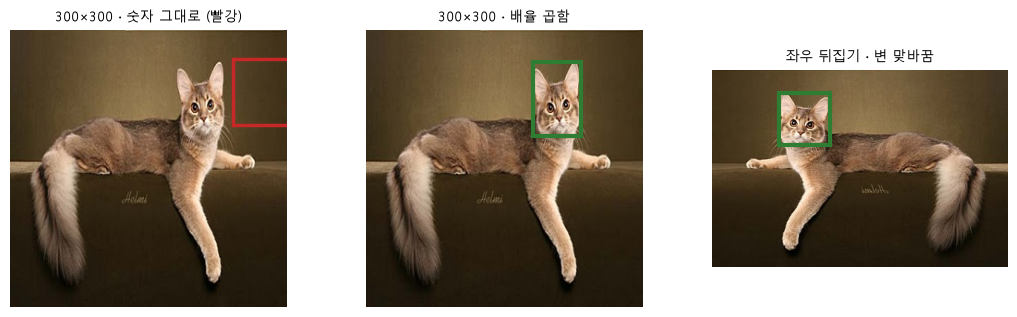

In [7]:
from torchvision import tv_tensors     # 박스용 텐서 종류
from torchvision.transforms import v2  # 사진 · 박스를 함께 바꾸는 변환

W, H = cat_img.size        # 원래 크기
x1, y1, x2, y2 = boxes[0]  # 원래 박스


# 크기 바꾸기: x는 가로 배율, y는 세로 배율
small = cat_img.resize((300, 300))                       # SSD 입력 크기
sx, sy = 300 / W, 300 / H                                # 가로 · 세로 배율이 다름
scaled = [x1 * sx, y1 * sy, x2 * sx, y2 * sy]            # x는 가로 배율 · y는 세로 배율
print(f"배율 가로 {sx:.3f} · 세로 {sy:.3f}")             # 두 배율 확인
print("배율 곱한 박스:", [round(v, 1) for v in scaled])  # 바뀐 박스


# 좌우 뒤집기: W - x 만 하면 왼쪽 · 오른쪽 변이 뒤바뀜
flipped = cat_img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)       # 사진 좌우 뒤집기
naive = [W - x1, y1, W - x2, y2]                                   # 틀린 방법: 변 순서 그대로
fixed = [W - x2, y1, W - x1, y2]                                   # 두 변을 맞바꿈
print("W - x 만 :", naive, "→ xmin < xmax?", naive[0] < naive[2])  # 왼쪽 > 오른쪽이 됨
print("변 맞바꿈:", fixed, "→ xmin < xmax?", fixed[0] < fixed[2])  # 순서가 맞는지


# 라이브러리 검증: v2는 사진과 박스를 함께 바꿈
bb = tv_tensors.BoundingBoxes([boxes[0]], format="XYXY",          # 박스임을 알려 줘야 함께 변환
                              canvas_size=(H, W))                 # (세로, 가로)
_, bb_small = v2.Resize((300, 300))(cat_img, bb)                  # 사진 · 박스 한 번에 크기 변경
_, bb_flip = v2.RandomHorizontalFlip(p=1.0)(cat_img, bb)          # p=1 → 항상
print("v2 Resize:", [round(v, 1) for v in bb_small[0].tolist()])  # 손계산과 비교
print("v2 Flip  :", bb_flip[0].tolist())                          # 손계산과 비교


# 그림: 숫자 그대로(빨강) · 배율 곱함 · 뒤집고 변 맞바꿈
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))                        # 세 경우 나란히
draw_box(show(small, title="300×300 · 숫자 그대로 (빨강)", ax=axes[0]),  # 틀린 박스
         boxes[0], BAD_COLOR)
show(small, gt=[scaled], title="300×300 · 배율 곱함", ax=axes[1])        # 맞는 박스
show(flipped, gt=[fixed], title="좌우 뒤집기 · 변 맞바꿈", ax=axes[2])   # 뒤집은 박스
plt.show()                                                               # 그림 출력

**결과** · 예측 정답은 xmin이 xmax보다 커짐 (159 > 90) — 뒤집히면 왼쪽 변과 오른쪽 변이 서로 바뀌므로 맞바꿔야 함

- `배율 가로 0.750 · 세로 1.124` — 300 ÷ 400 = 0.750, 300 ÷ 267 = 1.124 → 가로 · 세로 배율이 다름
- `배율 곱한 박스: [180.8, 34.8, 232.5, 114.6]` — x는 0.75배, y는 1.124배 → 초록 박스가 얼굴에 맞음 (빨강 = 숫자 그대로)
- `W - x 만 : [159.0, 31.0, 90.0, 102.0] → xmin < xmax? False` — 400 - 241 = 159가 xmin 자리 → 모서리 순서가 뒤집힘
- `변 맞바꿈: [90.0, 31.0, 159.0, 102.0] → xmin < xmax? True` — xmin = 400 - 310 = 90, xmax = 400 - 241 = 159
- `v2 Resize: [180.8, 34.8, 232.5, 114.6]` — 손계산과 같음 → 라이브러리가 박스도 함께 바꿈
- `v2 Flip  : [90.0, 31.0, 159.0, 102.0]` — 두 변을 맞바꾼 손계산과 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">사진만 바꾸기 (v1 · PIL)</td>
<td style="text-align: left;">박스 숫자는 그대로 → 정답이 어긋남</td>
<td style="text-align: left;">분류 (정답이 클래스 하나뿐)</td>
</tr>
<tr>
<td style="text-align: left;">손으로 박스도 계산</td>
<td style="text-align: left;">배율 곱 · <code>W - x</code> 후 두 변 맞바꿈</td>
<td style="text-align: left;">원리 확인 · 변환 하나뿐일 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>v2</code> + <code>BoundingBoxes</code></td>
<td style="text-align: left;">사진과 박스를 한 번에 같은 변환</td>
<td style="text-align: left;">탐지 학습 증강 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">크기 바꾸기 vs 좌우 뒤집기</td>
<td style="text-align: left;">배율 곱 (변 순서 유지) vs 좌표 반전 (왼쪽 · 오른쪽 변 교체)</td>
<td style="text-align: left;">둘 다 박스 변환 필요</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 옛 `transforms.RandomHorizontalFlip`(v1)은 사진만 뒤집음 → 박스는 그대로라 정답이 틀어짐, 탐지는 `transforms.v2` + `tv_tensors.BoundingBoxes`

> ✅ **한 줄 정리** · 크기를 바꾸면 x · y에 각각의 배율을 곱하고, 좌우로 뒤집으면 `W - x` 후 두 변을 맞바꾼다.

**딥러닝 코드에서는**

- 탐지 증강은 `v2.RandomHorizontalFlip(0.5)(img, target)`처럼 사진과 target을 함께 넘김 (객체탐지-2)

### 2-4. `A` 탐지 데이터 점검 · `Counter()` <sub>Day01 D1-9</sub>

> 🎯 **학습 전에 탐지 데이터의 목록 · 정답 · 박스를 어떻게 점검하는가?**

💡 **쉽게 말하면**

- 택배를 뜯기 전에 **송장과 내용물을 대조**하는 것.
- 사진 목록 · XML 유무 · 박스 숫자 · 이름 개수를 먼저 세어 보면 학습 중 터질 문제를 미리 찾음.

**실행 흐름**

1. trainval · test 목록 읽기
2. XML 있는 사진 세기
3. XML 전부 읽기
4. 박스 점검 3가지
5. 이름 개수 · 박스 2개인 사진

**먼저 예측** · 공식 test 목록 3669장 중 XML 정답이 있는 사진은 몇 장일까? — 답은 코드 실행 결과 아래에

In [8]:
# 목록 파일: "Abyssinian_100 1 1 1" → 앞 이름만
def read_list(name):                                      # 목록 txt → 사진 이름
    return [line.split()[0] for line in open(ANN / name)  # 줄의 첫 단어 = 사진 이름
            if line.strip() and not line.startswith("#")]


trainval, test = read_list("trainval.txt"), read_list("test.txt")  # 공식 두 목록
xml_stems = {p.stem for p in XMLS.glob("*.xml")}                   # 정답이 있는 사진 이름 집합
print("trainval", len(trainval), "장 | XML 있음",                  # 정답 있는 사진 수
      sum(s in xml_stems for s in trainval))
print("test    ", len(test), "장 | XML 있음",                      # test에도 있는지
      sum(s in xml_stems for s in test))


# 모든 XML 읽기: 이름 → (너비, 높이, 박스들, 이름들)
records = {}                                         # 사진 이름 → 정보
for s in sorted(xml_stems):                          # 이름순 → 매번 같은 순서
    root = ET.parse(XMLS / f"{s}.xml").getroot()     # 크기를 읽으려고 XML 열기
    records[s] = (int(root.findtext("size/width")),  # (너비, 높이, 박스, 이름)
                  int(root.findtext("size/height")), *read_voc(s))


# 박스 점검 3가지
problems = Counter()                                                     # 문제 종류별 개수
for w, h, bxs, _ in records.values():                                    # 사진마다
    for bx1, by1, bx2, by2 in bxs:                                       # 박스마다
        problems["사진 밖"] += bx1 < 0 or by1 < 0 or bx2 > w or by2 > h  # True = 1로 더함
        problems["xmin ≥ xmax"] += bx1 >= bx2                            # 가로 순서 오류
        problems["ymin ≥ ymax"] += by1 >= by2                            # 세로 순서 오류
print("박스", sum(len(r[2]) for r in records.values()), "개 | 문제:",    # 전체 박스 · 문제 수
      dict(problems))


# 이름별 개수 · 박스 2개인 사진
print("이름:", dict(Counter(n for *_, ns in records.values() for n in ns)))  # 클래스 불균형
print("박스 2개 사진:", [s for s, r in records.items() if len(r[2]) > 1])    # 물체 2개 사진

trainval 3680 장 | XML 있음 3671
test     3669 장 | XML 있음 0


박스 3687 개 | 문제: {'사진 밖': 0, 'xmin ≥ xmax': 0, 'ymin ≥ ymax': 0}
이름: {'cat': 1189, 'dog': 2498}
박스 2개 사진: ['Bengal_105']


**결과** · 예측 정답은 `0`장 — 공식 test에는 머리 박스 정답이 없음 → 채점용 사진은 trainval에서 따로 떼어야 함

- `trainval 3680 장 | XML 있음 3671` — 학습 · 검증 목록 중 9장은 XML 없음
- `test     3669 장 | XML 있음 0` — test에는 정답 XML이 없음 (채점 불가)
- `박스 3687 개 | 문제: {'사진 밖': 0, 'xmin ≥ xmax': 0, 'ymin ≥ ymax': 0}` — XML마다 박스 하나 + Bengal_105만 2개, 점검 3가지 모두 0건
- `이름: {'cat': 1189, 'dog': 2498}` — 개 박스가 고양이의 2배가 넘음 (클래스 불균형)
- `박스 2개 사진: ['Bengal_105']` — 고양이 두 마리 → 2-5에서 boxes 모양이 [2, 4]

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>trainval.txt</code> · <code>test.txt</code></td>
<td style="text-align: left;">공식 분할 목록 (사진 이름 + 품종 번호)</td>
<td style="text-align: left;">어떤 사진을 학습 · 평가에 쓸지</td>
</tr>
<tr>
<td style="text-align: left;">XML 있음 / 없음</td>
<td style="text-align: left;">trainval 3671장만 머리 박스 정답</td>
<td style="text-align: left;">탐지는 XML 있는 사진만 사용</td>
</tr>
<tr>
<td style="text-align: left;">박스 점검 (범위 · 순서)</td>
<td style="text-align: left;">숫자 오류 찾기</td>
<td style="text-align: left;">학습 전 1회</td>
</tr>
<tr>
<td style="text-align: left;">이름 개수 (<code>Counter</code>)</td>
<td style="text-align: left;">클래스 불균형 확인</td>
<td style="text-align: left;">AP를 클래스별로 볼 이유 (6-4)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 점검 없이 학습하면 xmin ≥ xmax 박스 하나 때문에 손실이 nan이 되거나 학습 중간에 에러 → 학습 전에 한 번 전체 점검

> ✅ **한 줄 정리** · 학습 전에 목록 · 정답 유무 · 박스 범위 · 클래스 개수를 세어 데이터 계약을 확인한다.

**딥러닝 코드에서는**

- `assert (boxes[:, 2] > boxes[:, 0]).all()` 같은 점검을 `Dataset`을 만들 때 한 번 실행

### 2-5. `A` 한 샘플 = 이미지 + target · `target 딕셔너리` · `int64` <sub>Day01 D1-9</sub>

> 🎯 **탐지 모델이 받는 한 샘플은 어떤 모양 · 자료형이어야 하는가?**

💡 **쉽게 말하면**

- 한 샘플은 **사진 + 정답 봉투**.
- 봉투(target 딕셔너리) 안에 boxes(실수, [N, 4])와 labels(정수, [N])를 넣는 약속이고, 형식이 틀리면 모델이 받지 않음.

**실행 흐름**

1. 이름
2. 번호 (0 = 배경) · `make_target`
3. image · boxes · labels 모양과 자료형
4. 박스 2개 사진
5. 약속을 어긴 target 2가지를 학습 모드 모델에 넣기

**먼저 예측** · labels를 실수형으로 넣어도 학습이 돌아갈까? — 답은 코드 실행 결과 아래에

In [9]:
import torchvision.transforms.functional as TF  # PIL → 텐서 함수

# 번호 약속: 0 = 배경 (XML에는 없음), 1 = 고양이 얼굴, 2 = 개 얼굴
CLASSES = ["배경", "고양이 얼굴", "개 얼굴"]  # 번호 → 이름
NAME_TO_LABEL = {"cat": 1, "dog": 2}          # 0은 배경 자리라 1부터


# 한 샘플 = 이미지 텐서 + target 딕셔너리
def make_target(stem):                                        # 사진 이름 → target 딕셔너리
    bxs, ns = read_voc(stem)                                  # XML의 박스 · 이름
    return {"boxes": torch.tensor(bxs, dtype=torch.float32),  # [N, 4]
            "labels": torch.tensor([NAME_TO_LABEL[n] for n in ns],
                                   dtype=torch.int64)}        # [N]


image = TF.to_tensor(load_image("Abyssinian_173"))                     # (3, H, W) · 0~1
t = make_target("Abyssinian_173")                                      # 한 장의 정답
print("image :", tuple(image.shape), image.dtype)                      # (3, H, W) · float32
print("boxes :", tuple(t["boxes"].shape), t["boxes"].dtype)            # (N, 4) · float32
print("labels:", tuple(t["labels"].shape), t["labels"].dtype)          # (N,) · int64
print("Bengal_105:", tuple(make_target("Bengal_105")["boxes"].shape),  # 박스 2개 사진
      make_target("Bengal_105")["labels"].tolist())


# 약속을 어기면? 학습 모드 모델(구조만 · 가중치 없음)에 넣어 보기
trainee = ssd300_vgg16(weights=None, weights_backbone=None,     # 다운로드 없이 구조만
                       num_classes=3).train()
cases = {"정상": t,                                             # 정상 · 틀린 target 두 가지
         "labels 실수형": {"boxes": t["boxes"], "labels": t["labels"].float()},
         "boxes 1차원": {"boxes": t["boxes"][0], "labels": t["labels"]}}
for name, target in cases.items():                              # 경우마다 학습 모드로 넣어 봄
    try:
        losses = trainee([image], [target])                     # 학습 모드 → 손실 dict
        print(f"[{name}] → 손실 dict {list(losses)}")           # 통과하면 손실 이름
    except (RuntimeError, AssertionError) as e:                 # 약속 위반 에러만 잡음
        print(f"[{name}] → {type(e).__name__}: {str(e)[:52]}")  # 에러 종류 · 앞부분

image : (3, 267, 400) torch.float32
boxes : (1, 4) torch.float32
labels: (1,) torch.int64
Bengal_105: (2, 4) [1, 1]


[정상] → 손실 dict ['bbox_regression', 'classification']
[labels 실수형] → RuntimeError: expected scalar type Long but found Float
[boxes 1차원] → AssertionError: Expected target boxes to be a tensor of shape [N, 4]


**결과** · 예측 정답은 `RuntimeError` — 분류 손실(cross-entropy)은 정수(Long) 라벨만 받음

- `image : (3, 267, 400) torch.float32` — (채널, 세로, 가로) · 0~1 실수
- `boxes : (1, 4) torch.float32` — [박스 수, 4] 실수 · xyxy
- `labels: (1,) torch.int64` — [박스 수] 정수 · 1 = 고양이 얼굴
- `Bengal_105: (2, 4) [1, 1]` — 박스가 2개면 boxes [2, 4] · labels 2개
- `[정상] → 손실 dict ['bbox_regression', 'classification']` — 학습 모드 + 올바른 target → 박스 대신 손실 2개
- `[labels 실수형] → RuntimeError: expected scalar type Long but found Float` — labels는 int64여야 함
- `[boxes 1차원] → AssertionError: Expected target boxes to be a tensor of shape [N, 4]` — 박스가 하나여도 [1, 4]로 감싸야 함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 샘플 <code>(image, 3)</code></td>
<td style="text-align: left;">정답 = 정수 하나</td>
<td style="text-align: left;">사진 하나에 클래스 하나</td>
</tr>
<tr>
<td style="text-align: left;">탐지 샘플 <code>(image, target)</code></td>
<td style="text-align: left;">정답 = 딕셔너리 (박스 N개 + 라벨 N개)</td>
<td style="text-align: left;">사진마다 물체 수가 다를 때</td>
</tr>
<tr>
<td style="text-align: left;">학습 모드 <code>model.train()</code></td>
<td style="text-align: left;">target을 받아 손실 dict 반환</td>
<td style="text-align: left;">학습 루프 (객체탐지-2)</td>
</tr>
<tr>
<td style="text-align: left;">평가 모드 <code>model.eval()</code></td>
<td style="text-align: left;">사진만 받아 박스 dict 반환</td>
<td style="text-align: left;">예측 · 채점 (1-2 · 7장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 0번은 배경 자리 → 우리 클래스는 1부터 번호를 붙이고, 모델의 `num_classes`는 배경 포함 3 (배경 · 고양이 얼굴 · 개 얼굴)

> ✅ **한 줄 정리** · 탐지 한 샘플은 이미지 텐서와 `{"boxes": float32 [N, 4], "labels": int64 [N]}` 딕셔너리이고, 번호 0은 배경이다.

**딥러닝 코드에서는**

- `Dataset.__getitem__`이 `return image, target`, 학습은 `loss_dict = model(images, targets)` (객체탐지-2에서 collate_fn과 함께)

---
## 3. IoU

> **이 장의 흐름**
>
> - 2장에서 예측과 정답을 같은 xyxy 형식으로 맞췄다 → 두 박스가 얼마나 겹치는지를 0~1 숫자 하나로 잼.
> - 손계산과 라이브러리 결과를 대조해 식을 확인

**파이프라인 위치** · ⑥ 평가 — 박스 하나의 맞은 정도 (5장 짝짓기의 재료)

### 3-1. `A` IoU 손계산과 검증 · `box_iou()` <sub>Day01 D1-4 · 보충 A1</sub>

> 🎯 **예측 박스가 정답과 얼마나 맞았는지를 숫자 하나로 어떻게 재는가?**

💡 **쉽게 말하면**

- IoU는 **두 종이를 겹쳤을 때 겹친 넓이 ÷ 두 종이가 차지한 전체 넓이**.
- 딱 포개지면 1, 안 겹치면 0, 너무 크거나 작아도 낮아짐.

<img src="images/od1_iou.png" alt="IoU = 겹친 넓이 ÷ 합친 넓이" width="744">

**실행 흐름**

1. 겹친 가로 · 세로
2. 겹친 넓이
3. 합친 넓이 = 두 넓이 - 겹친 넓이
4. 손계산 함수
5. `box_iou` 결과와 한 줄씩 대조

**먼저 예측** · 정답(한 변 100)을 오른쪽으로 50 밀면 IoU는 0.5일까? — 답은 코드 실행 결과 아래에

In [10]:
from torchvision.ops import box_iou  # IoU 표를 한 번에


# IoU 손계산: 겹친 넓이 ÷ 합친 넓이
def iou_hand(a, b):                           # 박스 두 개 → IoU
    w = min(a[2], b[2]) - max(a[0], b[0])     # 겹친 가로
    h = min(a[3], b[3]) - max(a[1], b[1])     # 겹친 세로
    inter = max(w, 0) * max(h, 0)             # 안 겹치면 음수 → 0
    area_a = (a[2] - a[0]) * (a[3] - a[1])    # 너비 × 높이
    area_b = (b[2] - b[0]) * (b[3] - b[1])    # 너비 × 높이
    return inter / (area_a + area_b - inter)  # 겹친 부분은 한 번만


gt_box = [100, 100, 200, 200]                # 정답 (한 변 100)
cands = {"A 10 밀기": [110, 100, 210, 200],  # 정답과 비교할 예측 5개
         "B 50 밀기": [150, 100, 250, 200],
         "C 넓이 2배": [79.3, 79.3, 220.7, 220.7],
         "D 넓이 절반": [114.6, 114.6, 185.4, 185.4],
         "E 안 겹침": [300, 300, 400, 400]}


# 라이브러리: 정답 1개 × 예측 5개 → (1, 5) 표
lib = box_iou(torch.tensor([gt_box], dtype=torch.float64),        # float64 → 손계산과 정확히 비교
              torch.tensor(list(cands.values()), dtype=torch.float64))
print("box_iou 모양:", tuple(lib.shape), "= (정답 수, 예측 수)")  # 행 = 첫 인자


# 검증표: 손계산 vs box_iou
for (name, p), v in zip(cands.items(), lib[0].tolist()):  # 예측마다 두 값 짝짓기
    mine = iou_hand(gt_box, p)                            # 손계산
    # 아주 작은 차이도 잡음
    print(f"손계산 {mine:.4f} | box_iou {v:.4f} | 같음 {abs(mine - v) < 1e-9}"
          f" | {name}")

box_iou 모양: (1, 5) = (정답 수, 예측 수)
손계산 0.8182 | box_iou 0.8182 | 같음 True | A 10 밀기
손계산 0.3333 | box_iou 0.3333 | 같음 True | B 50 밀기
손계산 0.5002 | box_iou 0.5002 | 같음 True | C 넓이 2배
손계산 0.5013 | box_iou 0.5013 | 같음 True | D 넓이 절반
손계산 0.0000 | box_iou 0.0000 | 같음 True | E 안 겹침


**결과** · 예측 정답은 `0.3333` — 겹친 넓이 50 × 100 = 5000, 합친 넓이 10000 + 10000 - 5000 = 15000

- `box_iou 모양: (1, 5) = (정답 수, 예측 수)` — N개 × M개를 표 하나로 계산 (행 = 첫 인자, 열 = 둘째 인자)
- `손계산 0.8182 | box_iou 0.8182 | 같음 True | A 10 밀기` — 겹친 90 × 100 = 9000, 합친 20000 - 9000 = 11000
- `손계산 0.3333 | box_iou 0.3333 | 같음 True | B 50 밀기` — 반만 겹쳤는데 IoU는 1/3
- `손계산 0.5002 | box_iou 0.5002 | 같음 True | C 넓이 2배` — 정답을 완전히 감싸도 넓이가 2배면 약 0.5
- `손계산 0.5013 | box_iou 0.5013 | 같음 True | D 넓이 절반` — 정답 안에 쏙 들어가도 넓이가 절반이면 약 0.5
- `손계산 0.0000 | box_iou 0.0000 | 같음 True | E 안 겹침` — 겹친 가로 · 세로가 음수 → 0으로 자름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>iou_hand(a, b)</code> 손계산</td>
<td style="text-align: left;">박스 두 개 → 숫자 하나, 반복문 필요</td>
<td style="text-align: left;">원리 확인 · 검산</td>
</tr>
<tr>
<td style="text-align: left;"><code>box_iou(A, B)</code></td>
<td style="text-align: left;">N개 × M개 → (N, M) 표를 한 번에</td>
<td style="text-align: left;">실제 코드 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">정답이 예측 안에 든 비율</td>
<td style="text-align: left;">큰 박스에 벌점이 없음</td>
<td style="text-align: left;">진단용 (IoU가 표준)</td>
</tr>
<tr>
<td style="text-align: left;">중심 거리 (픽셀)</td>
<td style="text-align: left;">박스 크기마다 의미가 달라짐</td>
<td style="text-align: left;">IoU는 0~1이라 크기와 무관하게 비교</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 겹친 가로 · 세로가 음수일 때 `max(·, 0)`을 빼먹으면 음수 × 음수가 양수가 되어, 안 겹친 박스의 IoU가 0보다 커짐

> ✅ **한 줄 정리** · IoU는 겹친 넓이 ÷ 합친 넓이(0 ~ 1)이고, 위치가 밀려도 크기가 달라도 낮아진다.

**딥러닝 코드에서는**

- `box_iou(pred_boxes, gt_boxes)` → (예측 수, 정답 수) 표 → 예측마다 가장 많이 겹친 정답 찾기 (5장 짝짓기)

### 3-2. `A` 박스 크기와 실제 사진의 IoU · `box_area()` <sub>Day01 D1-4</sub>

> 🎯 **같은 10픽셀 오차인데 IoU는 왜 다르고, 실제 사진에서 신뢰도 0.99 박스의 IoU는 왜 낮은가?**

💡 **쉽게 말하면**

- IoU는 **비율**이라 큰 박스의 10픽셀은 작은 흠, 작은 박스의 10픽셀은 절반이 사라지는 것.
- 또 모델이 배운 정답(몸 전체)과 우리 정답(머리)이 다르면 아무리 확신해도 겹침이 작음.

**실행 흐름**

1. 한 변 100 · 20 박스를 10픽셀 밀기
2. IoU 비교
3. 실제 사진 2장: COCO SSD 1등 박스 vs XML 머리 박스
4. 넓이 배수 · IoU

**먼저 예측** · 한 변 20인 박스를 10픽셀 밀면 IoU는? — 답은 코드 실행 결과 아래에

한 변 100 박스 → IoU 0.82
한 변  20 박스 → IoU 0.33


Russian_Blue_123 cat 0.99 | 예측 넓이 = 정답의 5.7배 | IoU 0.16


Birman_164       cat 0.97 | 예측 넓이 = 정답의 1.3배 | IoU 0.76


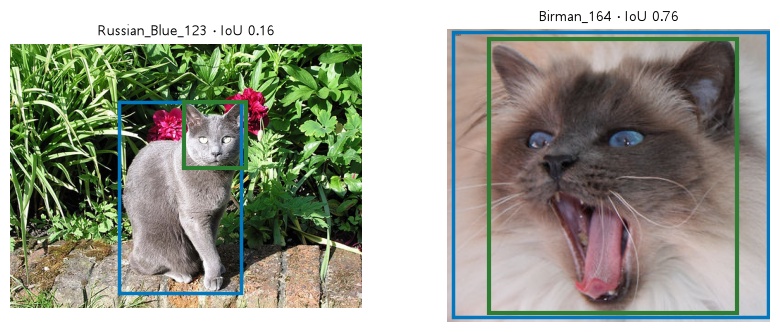

In [11]:
from torchvision.ops import box_area  # 박스 넓이

# 같은 10픽셀 밀기 · 박스 크기만 다름
big = torch.tensor([[100., 100., 200., 200.]])                             # 한 변 100
small_b = torch.tensor([[100., 100., 120., 120.]])                         # 한 변 20
shift = torch.tensor([10., 0., 10., 0.])                                   # 오른쪽으로 10픽셀
print("한 변 100 박스 → IoU", round(box_iou(big, big + shift).item(), 2))  # 큰 박스 10픽셀 오차
print("한 변  20 박스 → IoU",                                              # 작은 박스 10픽셀 오차
      round(box_iou(small_b, small_b + shift).item(), 2))


# 실제 사진: COCO 모델의 1등 박스 vs XML 정답(머리)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))                    # 두 사진 나란히
for stem, ax in zip(["Russian_Blue_123", "Birman_164"], axes):       # 강의의 두 사진
    img = load_image(stem)                                           # 사진 열기
    g = torch.tensor(read_voc(stem)[0])                              # 정답(머리) 박스
    o = run(detector, img)                                           # COCO 모델 예측
    top = o["boxes"][:1]  # 점수 1등 박스 (점수 높은 순으로 나옴)
    v = box_iou(top, g).item()                                       # 1등 박스와 정답의 IoU
    times = (box_area(top) / box_area(g)).item()                     # 예측이 정답의 몇 배 넓이
    print(f"{stem:16s} {COCO[o['labels'][0]]} {o['scores'][0]:.2f}"  # 이름 · 신뢰도 · 배수 · IoU
          f" | 예측 넓이 = 정답의 {times:.1f}배 | IoU {v:.2f}")
    show(img, gt=g, pred=top, title=f"{stem} · IoU {v:.2f}", ax=ax)  # 초록 vs 파랑
plt.show()                                                           # 그림 출력

**결과** · 예측 정답은 `0.33` — 겹친 10 × 20 = 200, 합친 400 + 400 - 200 = 600

- `한 변 100 박스 → IoU 0.82` — 10픽셀 = 한 변의 10% → 조금 감소
- `한 변  20 박스 → IoU 0.33` — 10픽셀 = 한 변의 절반 → 크게 감소 (작은 물체가 어려운 이유)
- `Russian_Blue_123 cat 0.99 | 예측 넓이 = 정답의 5.7배 | IoU 0.16` — 신뢰도 0.99인데 IoU 0.16 → 몸 전체 박스가 머리 정답보다 5.7배 큼
- `Birman_164       cat 0.97 | 예측 넓이 = 정답의 1.3배 | IoU 0.76` — 얼굴이 사진을 거의 채움 → 몸 박스 ≈ 머리 박스 → 우연히 높음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">큰 박스의 오차</td>
<td style="text-align: left;">같은 픽셀 오차도 IoU 감소가 작음</td>
<td style="text-align: left;">큰 물체 → 높은 IoU 기준(AP75)도 통과</td>
</tr>
<tr>
<td style="text-align: left;">작은 박스의 오차</td>
<td style="text-align: left;">몇 픽셀만 밀려도 IoU 급감</td>
<td style="text-align: left;">작은 물체 → 성능을 크기별로 따로 봄</td>
</tr>
<tr>
<td style="text-align: left;">신뢰도 (score)</td>
<td style="text-align: left;">모델이 낸 확신, 정답 없이도 있음</td>
<td style="text-align: left;">결과 거르기 (4장)</td>
</tr>
<tr>
<td style="text-align: left;">IoU</td>
<td style="text-align: left;">정답과의 겹침, 정답이 있어야 계산</td>
<td style="text-align: left;">채점 (5장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 신뢰도는 모델의 확신이지 정답과의 겹침이 아님 → 신뢰도 0.99도 IoU 0.16일 수 있음 (정답의 정의가 다르면 특히)

> ✅ **한 줄 정리** · IoU는 크기에 대한 비율이라 작은 물체일수록 같은 오차에 크게 떨어지고, 정답의 정의가 다르면 확신이 높아도 낮다.

**딥러닝 코드에서는**

- COCO 평가는 물체 크기별 AP(`map_small` · `map_medium` · `map_large`)를 따로 보고함 — 작은 물체 AP가 낮은 이유가 이 비율

---
## 4. 신뢰도 · NMS

> **이 장의 흐름**
>
> - 3장은 박스 하나였다 → 모델은 같은 물체에도 박스를 여러 개, 사진마다 수백 개를 냄.
> - 점수로 거르고(신뢰도 임곗값) 겹친 중복을 지워야(NMS) 최종 결과가 됨

**파이프라인 위치** · ④ 모델 출력 정리 — 후보 → 신뢰도로 거르기 → 클래스별 NMS

### 4-1. `A` 신뢰도와 임곗값 · `scores > 임곗값` <sub>Day01 D1-5</sub>

> 🎯 **신뢰도 임곗값을 바꾸면 결과 박스 수는 어떻게 바뀌고, 모델 안에는 어떤 기준이 미리 있는가?**

💡 **쉽게 말하면**

- 신뢰도는 **모델이 손을 드는 자신감**.
- 임곗값은 "몇 점 이상 자신 있는 것만 발표"라는 규칙이라, 낮추면 발표가 늘고 틀린 발표도 늘어남.

**실행 흐름**

1. 모델 안 기준 3가지 출력
2. 버먼 고양이 사진
3. 200줄 앞 3개
4. 임곗값 0.5 · 0.25 · 0.01마다 남는 수

**먼저 예측** · 신뢰도 > 0.01로 거르면 몇 개가 남을까? — 답은 코드 실행 결과 아래에

In [12]:
# 모델 안에 미리 정해진 기준
print("모델 안 신뢰도 하한:", detector.score_thresh,  # 출력 전에 이미 거르는 기준
      "| NMS 기준:", detector.nms_thresh,
      "| 최대 개수:", detector.detections_per_img)


# 버먼 고양이 한 마리 사진 → 출력 줄 수와 신뢰도
img_b = load_image("Birman_151")                              # 버먼 고양이 사진
out_b = run(detector, img_b)                                  # 예측
print("출력 박스 수:", len(out_b["scores"]))                  # 최대 200줄
for lab, s in zip(out_b["labels"][:3], out_b["scores"][:3]):  # 점수 높은 3줄
    print(f"  {COCO[lab]:9s} {s:.3f}")                        # 이름 · 신뢰도


# 신뢰도 임곗값을 내리면 남는 박스가 늘어남
for thr in (0.5, 0.25, 0.01):                                           # 임곗값을 내려 가며
    print(f"신뢰도 > {thr}: {(out_b['scores'] > thr).sum().item()}개")  # 남는 박스 수

모델 안 신뢰도 하한: 0.01 | NMS 기준: 0.45 | 최대 개수: 200


출력 박스 수: 200
  cat       0.845
  cat       0.344
  suitcase  0.266
신뢰도 > 0.5: 1개
신뢰도 > 0.25: 3개
신뢰도 > 0.01: 200개


**결과** · 예측 정답은 `200`개 전부 — 모델 안에서 이미 0.01 넘는 것만 최대 200개까지 냈기 때문

- `모델 안 신뢰도 하한: 0.01 | NMS 기준: 0.45 | 최대 개수: 200` — 출력 전에 모델 안에서 이미 거르는 기준 3가지
- `cat       0.845` — 1등 = 고양이 (정답)
- `cat       0.344` — 2등도 고양이 → 같은 고양이를 다른 자리에 친 박스 (4-3)
- `suitcase  0.266` — 3등은 엉뚱한 클래스
- `신뢰도 > 0.5: 1개` — 엄격 → 고양이 하나만
- `신뢰도 > 0.25: 3개` — 느슨 → 엉뚱한 suitcase까지
- `신뢰도 > 0.01: 200개` — 모델 안 하한과 같음 → 전부 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">모델 안 하한 <code>score_thresh</code> (0.01)</td>
<td style="text-align: left;">출력 전에 모델이 거름</td>
<td style="text-align: left;">평가용 예측을 넉넉히 모을 때 (낮게 유지)</td>
</tr>
<tr>
<td style="text-align: left;">내가 정하는 신뢰도 임곗값 (0.5 등)</td>
<td style="text-align: left;">출력 뒤에 거름</td>
<td style="text-align: left;">화면 · 서비스에 보여 줄 결과</td>
</tr>
<tr>
<td style="text-align: left;"><code>detections_per_img</code> (200)</td>
<td style="text-align: left;">사진당 최대 개수</td>
<td style="text-align: left;">물체가 아주 많은 사진 (늘림)</td>
</tr>
<tr>
<td style="text-align: left;">높은 임곗값 vs 낮은 임곗값</td>
<td style="text-align: left;">정밀도↑ 재현율↓ vs 재현율↑ 정밀도↓</td>
<td style="text-align: left;">오탐이 비쌀 때 높게 · 놓침이 비쌀 때 낮게</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 신뢰도 임곗값은 결과를 보여 줄 기준 → AP를 계산할 때는 더 자르지 않고 낮은 점수까지 모두 씀 (6-2)

> ✅ **한 줄 정리** · 신뢰도 임곗값을 낮추면 박스가 늘어 놓침은 줄지만 틀린 박스도 늘어나므로, 목적에 맞게 정한다.

**딥러닝 코드에서는**

- `keep = out["scores"] > 0.5` 한 줄이 화면 결과를 정함, 모델 안 기준은 `model.score_thresh`(SSD) · `model.roi_heads.score_thresh`(Faster R-CNN)

### 4-2. `A` NMS 손구현과 검증 · `nms()` · `batched_nms()` <sub>Day01 D1-5</sub>

> 🎯 **같은 물체에 겹쳐 나온 박스 여러 개를 하나로 정리하는 NMS는 어떻게 동작하는가?**

💡 **쉽게 말하면**

- NMS는 **단체 사진에서 같은 사람이 여러 번 찍힌 것 지우기**.
- 가장 잘 나온 한 장(최고 점수)을 남기고, 그와 많이 겹친 것을 지운 뒤, 남은 것 중에서 또 반복.

<img src="images/od1_nms.png" alt="NMS: 1등을 남기고 많이 겹친 후보를 지우기를 반복" width="763">

**실행 흐름**

1. 후보 6개 (물체 1 근처 5개 + 물체 2)
2. 0번과 IoU
3. 손구현 NMS
4. `nms()` 결과 대조
5. `batched_nms` (클래스 구분)
6. 몸 vs 머리 박스

**먼저 예측** · IoU 기준 0.5로 NMS를 하면 6개 중 몇 개가 남을까? — 답은 코드 실행 결과 아래에

In [13]:
from torchvision.ops import batched_nms, nms  # 라이브러리 NMS 두 가지


# NMS 손구현: 1등을 남기고, 1등과 많이 겹친 후보를 지움 → 반복
def nms_hand(boxes, scores, iou_thr):                            # 직접 만든 NMS
    order = scores.argsort(descending=True).tolist()             # 점수 높은 순 번호
    keep = []                                                    # 남길 번호
    while order:                                                 # 후보가 남아 있는 동안
        top = order.pop(0)                                       # 남은 것 중 1등 → 남김
        keep.append(top)                                         # 1등은 무조건 남김
        if order:                                                # 비교할 후보가 있을 때만
            ious = box_iou(boxes[top:top + 1], boxes[order])[0]  # 1등과 나머지의 IoU
            order = [i for i, v in zip(order, ious.tolist())     # 기준 이하만 다음 차례로
                     if v <= iou_thr]                            # 기준 넘게 겹친 후보 지움
    return keep                                                  # 남은 번호 목록


# 같은 클래스 후보 6개: 물체 1 근처 5개 + 물체 2 하나
cand = torch.tensor([[100, 100, 200, 200], [105, 102, 205, 198],       # 물체 1 근처 5개 + 물체 2
                     [98, 95, 195, 205], [110, 110, 210, 210],
                     [90, 100, 190, 200], [400, 100, 480, 220]],
                    dtype=torch.float)
sc = torch.tensor([0.95, 0.90, 0.85, 0.80, 0.70, 0.88])                # 후보마다 신뢰도
print("0번과 IoU:",                                                    # 1등과 얼마나 겹치나
      [round(v, 2) for v in box_iou(cand[:1], cand)[0].tolist()])
print("손구현 남은 번호:", nms_hand(cand, sc, 0.5))                    # 직접 만든 결과
print("nms()  남은 번호:", nms(cand, sc, iou_threshold=0.5).tolist())  # 라이브러리와 비교


# 클래스를 구분하는 batched_nms: 완전히 같은 박스 2개
same = torch.tensor([[0, 0, 10, 10], [0, 0, 10, 10]], dtype=torch.float)  # 완전히 같은 박스 2개
s2 = torch.tensor([0.9, 0.6])                                             # 두 박스 신뢰도
print("같은 클래스:",                                                     # 클래스가 같으면 / 다르면
      batched_nms(same, s2, torch.tensor([1, 1]), 0.5).tolist(),
      "| 다른 클래스:",
      batched_nms(same, s2, torch.tensor([1, 2]), 0.5).tolist())


# NMS가 못 하는 것: 같은 고양이의 몸 박스 · 머리 박스
body_head = torch.tensor([[100, 100, 200, 300], [100, 100, 200, 170]],  # 몸 · 머리 박스
                         dtype=torch.float)
print("몸 vs 머리 IoU:",                                                # 겹침이 작으면 둘 다 남음
      round(box_iou(body_head[:1], body_head[1:]).item(), 2),
      "| NMS 뒤 남은 번호:", nms(body_head, s2, 0.5).tolist())

0번과 IoU: [1.0, 0.87, 0.85, 0.68, 0.82, 0.0]
손구현 남은 번호: [0, 5]
nms()  남은 번호: [0, 5]
같은 클래스: [0] | 다른 클래스: [0, 1]
몸 vs 머리 IoU: 0.35 | NMS 뒤 남은 번호: [0, 1]


**결과** · 예측 정답은 `2`개 (0번 · 5번) — 0번과 0.5 넘게 겹친 1 ~ 4번이 지워지고, 안 겹친 5번(물체 2)은 남음

- `0번과 IoU: [1.0, 0.87, 0.85, 0.68, 0.82, 0.0]` — 1 ~ 4번은 0.5 넘게 겹침, 5번은 0
- `손구현 남은 번호: [0, 5]` — 1등(0번) 남김 → 겹친 4개 지움 → 남은 5번 남김
- `nms()  남은 번호: [0, 5]` — 라이브러리 결과와 같음
- `같은 클래스: [0] | 다른 클래스: [0, 1]` — `batched_nms`는 클래스가 다르면 완전히 겹쳐도 지우지 않음
- `몸 vs 머리 IoU: 0.35 | NMS 뒤 남은 번호: [0, 1]` — 같은 고양이라도 IoU가 기준보다 낮으면 둘 다 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nms(boxes, scores, iou)</code></td>
<td style="text-align: left;">클래스 구분 없이 모두 비교</td>
<td style="text-align: left;">클래스가 하나뿐일 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>batched_nms(boxes, scores, labels, iou)</code></td>
<td style="text-align: left;">같은 클래스끼리만 비교</td>
<td style="text-align: left;">여러 클래스 탐지 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">NMS 기준 낮음 (0.3)</td>
<td style="text-align: left;">조금만 겹쳐도 지움</td>
<td style="text-align: left;">물체끼리 떨어져 있을 때</td>
</tr>
<tr>
<td style="text-align: left;">NMS 기준 높음 (0.7)</td>
<td style="text-align: left;">많이 겹쳐야 지움 → 중복이 남기 쉬움</td>
<td style="text-align: left;">물체끼리 붙어 있을 때 (사람 무리)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `nms()`는 클래스를 모름 → 고양이 박스가 개 박스를 지울 수 있음, 여러 클래스면 `batched_nms(boxes, scores, labels, iou)`

> ✅ **한 줄 정리** · NMS는 점수 1등을 남기고 그와 IoU가 기준을 넘는 후보를 지우는 일을 반복해, 겹친 중복 박스를 정리한다.

**딥러닝 코드에서는**

- torchvision 탐지 모델은 출력 직전에 `batched_nms`를 이미 실행 (`model.nms_thresh` = 0.45), ultralytics YOLO는 `predict(iou=...)`로 조절

### 4-3. `A` NMS 전 후보와 NMS 후 결과 · `nms_thresh` <sub>Day01 D1-5 · D1-6</sub>

> 🎯 **NMS 전 후보와 NMS 후 결과는 몇 개씩이고, 직접 정리한 결과는 모델 출력과 같은가?**

💡 **쉽게 말하면**

- 모델 속에는 **편집 전 원고**(NMS 전 후보 1708개)가 있고, 우리가 받는 출력은 **편집된 기사**(NMS 후).
- 편집 규칙을 직접 적용해 보면 같은 기사가 나옴.

**실행 흐름**

1. NMS를 끈 복사본
2. 전 · 후 개수 · 후보
3. 신뢰도 > 0.3
4. `batched_nms`(0.45) 직접
5. 모델 출력과 비교
6. NMS 기준 0.3 · 0.45 · 0.7 · 그림

**먼저 예측** · NMS와 200개 제한을 끄면 이 사진의 후보는 몇 개일까? — 답은 코드 실행 결과 아래에

NMS 전: 전체 1708개 | 신뢰도 > 0.3: 5 개
NMS 후: 전체 200개 | 신뢰도 > 0.3: 2 개


후보 1708 → 신뢰도 거름 5 → NMS 2
직접 정리: [0.84, 0.34]
모델 출력: [0.84, 0.34]
NMS 기준 0.3: 남은 점수 [0.84]
NMS 기준 0.45: 남은 점수 [0.84, 0.34]
NMS 기준 0.7: 남은 점수 [0.84, 0.34]


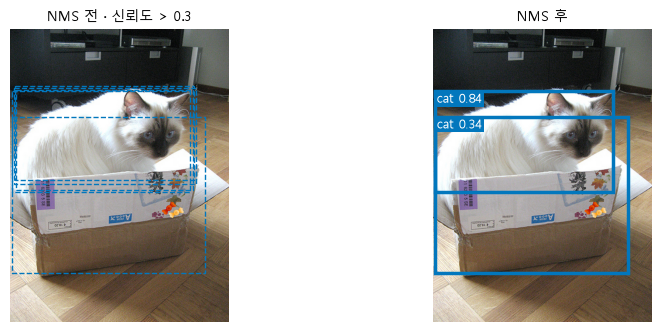

In [14]:
# NMS를 끈 복사본: IoU > 1.0 인 경우는 없음 → 아무것도 안 지움
raw = copy.deepcopy(detector)                            # 원래 모델은 그대로 두고 복사본만 바꿈
raw.nms_thresh = 1.0                                     # IoU > 1.0은 없음 → NMS가 아무것도 안 지움
raw.detections_per_img = 10 ** 6                         # 최대 200개 제한도 풂
before, after = run(raw, img_b), run(detector, img_b)    # NMS 전 · 후 예측
for name, o in (("NMS 전", before), ("NMS 후", after)):  # 두 결과 비교
    print(f"{name}: 전체 {len(o['scores'])}개 | 신뢰도 > 0.3:",  # 전체 · 0.3 넘는 수
          (o["scores"] > 0.3).sum().item(), "개")


# 탐지 마지막 단계: 후보 → 신뢰도로 거르기 → 클래스별 NMS
def detect(img, score_thr=0.5, iou_thr=0.45):                   # 탐지 마지막 단계를 직접
    c = run(raw, img)                                           # NMS 전 후보
    k = c["scores"] > score_thr                                 # 1단계: 신뢰도로 거르기
    bx, s, lab = c["boxes"][k], c["scores"][k], c["labels"][k]  # 남은 후보만
    k2 = batched_nms(bx, s, lab, iou_thr)                       # 2단계: 클래스별 NMS
    print(f"후보 {len(c['scores'])} → 신뢰도 거름 {len(s)} → NMS {len(k2)}")  # 단계별 개수
    return bx[k2], s[k2], lab[k2]                               # 최종 박스 · 점수 · 라벨


bx, s, lab = detect(img_b, score_thr=0.3)                  # 0.3 기준으로 직접 정리
print("직접 정리:", [round(v, 2) for v in s.tolist()])     # 직접 정리한 점수
kept = after["scores"][after["scores"] > 0.3]              # 모델 출력 중 0.3 넘는 것
print("모델 출력:", [round(v, 2) for v in kept.tolist()])  # 모델 출력과 같은지


# NMS 기준(IoU)을 바꾸면
cb = before["scores"] > 0.3                                     # NMS 전 후보 중 0.3 넘는 것
for t in (0.3, 0.45, 0.7):                                      # NMS 기준을 바꿔 가며
    k = batched_nms(before["boxes"][cb], before["scores"][cb],  # 같은 후보에 다른 기준
                    before["labels"][cb], t)
    print(f"NMS 기준 {t}: 남은 점수",                           # 남은 박스 점수
          [round(v, 2) for v in before["scores"][cb][k].tolist()])


# 그림: NMS 전 후보(점선) vs NMS 후(실선)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))                            # 전 · 후 나란히
show(img_b, cand=before["boxes"][cb], title="NMS 전 · 신뢰도 > 0.3",         # 후보 = 점선
     ax=axes[0])
show(img_b, pred=bx, labels=[f"{COCO[i]} {v:.2f}" for i, v in zip(lab, s)],  # 최종 = 실선
     title="NMS 후", ax=axes[1])
plt.show()                                                                   # 그림 출력

**결과** · 예측 정답은 `1708`개 — 클래스마다 후보를 내기 때문, 신뢰도 > 0.3만 보면 5개 → NMS 뒤 2개

- `NMS 전: 전체 1708개 | 신뢰도 > 0.3: 5 개` — NMS · 200개 제한을 끈 후보
- `NMS 후: 전체 200개 | 신뢰도 > 0.3: 2 개` — 모델 기본 출력
- `후보 1708 → 신뢰도 거름 5 → NMS 2` — 탐지 마지막 단계 = 거르기 → 클래스별 NMS
- `직접 정리: [0.84, 0.34]` — 직접 두 단계를 적용한 결과
- `모델 출력: [0.84, 0.34]` — 모델 출력과 같음 → 모델 안에서 하는 일이 바로 이 두 단계
- `NMS 기준 0.3: 남은 점수 [0.84]` — 엄격 → 0.34 박스까지 지움
- `NMS 기준 0.45: 남은 점수 [0.84, 0.34]` — 기본값 · 두 박스의 IoU가 0.45보다 작아 둘 다 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">NMS 전 후보</td>
<td style="text-align: left;">같은 물체에 박스 여러 개 (1708개)</td>
<td style="text-align: left;">원리 확인 · 디버깅</td>
</tr>
<tr>
<td style="text-align: left;">NMS 후 출력</td>
<td style="text-align: left;">물체마다 대체로 박스 하나 (최대 200개)</td>
<td style="text-align: left;">평가 · 서비스 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">직접 <code>detect()</code></td>
<td style="text-align: left;">거르기 · NMS 기준을 바꿔 가며 실험</td>
<td style="text-align: left;">기준값 조정 실험</td>
</tr>
<tr>
<td style="text-align: left;">모델 설정 <code>model.nms_thresh = 0.3</code></td>
<td style="text-align: left;">모델 안 기준 자체를 바꿈</td>
<td style="text-align: left;">정한 기준을 계속 쓸 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - NMS 기준(예측끼리의 IoU)과 평가 IoU 임곗값(예측과 정답의 IoU)은 둘 다 IoU지만 쓰는 곳이 다름 → 6-3 기준 비교표

> ✅ **한 줄 정리** · 탐지 결과는 후보 → 신뢰도로 거르기 → 클래스별 NMS 순서로 만들어지고, NMS 전 후보는 중복 때문에 훨씬 많다.

**딥러닝 코드에서는**

- 평가 · 서비스 모두 NMS 후 출력을 씀 — NMS 전 후보로 채점하면 중복이 FP가 되어 AP가 떨어짐 (7장에서 확인)

---
## 5. 짝짓기 채점

> **이 장의 흐름**
>
> - 4장에서 최종 박스를 얻었다 → "맞혔다"를 정하려면 정답과 1 : 1로 짝지어 TP · FP · FN을 세야 함.
> - 손으로 검산할 수 있는 작은 예(사진 2장 · 정답 3개)로 규칙을 확인

**파이프라인 위치** · ⑥ 평가 — 기준 하나에서의 정밀도 · 재현율 · F1

### 5-1. `A` 정답과 짝짓기 · `TP · FP · FN` <sub>Day01 D1-11 · 보충 A2 ~ A4</sub>

> 🎯 **예측 박스가 맞았다(TP) · 틀렸다(FP), 정답을 놓쳤다(FN)는 어떤 규칙으로 정하는가?**

💡 **쉽게 말하면**

- 짝짓기는 **댄스파티 짝 정하기**.
- 신뢰도 높은 예측부터 차례로, 아직 짝 없는 정답 중 가장 많이 겹친 상대와 짝이 됨(IoU 0.5 이상일 때만).
- 이미 짝 있는 정답에 또 다가간 예측은 중복(FP).

<img src="images/od1_matching.png" alt="짝짓기 규칙: 신뢰도 높은 순 → TP · FP · FN" width="763">

**실행 흐름**

1. 정답 3개 · 예측 6개
2. 신뢰도 높은 순 정렬
3. 같은 사진의 짝 없는 정답 중 IoU 최대
4. 0.5 이상 TP · 아니면 FP
5. 남은 정답 = FN

**먼저 예측** · 0.80 박스는 사진1 왼쪽 정답과 IoU 0.85인데 판정은? — 답은 코드 실행 결과 아래에

In [15]:
# 손으로 검산할 수 있는 예: 사진 2장 · 고양이 얼굴 정답 3개
GT = {"사진1": [[10, 10, 60, 60], [100, 20, 150, 70]],  # 사진별 정답 박스
      "사진2": [[30, 30, 90, 90]]}


# 모델 A의 예측 6개: (신뢰도, 사진, 박스)
PRED_A = [(0.95, "사진1", [12, 12, 60, 62]),  # (신뢰도, 사진, 박스)
          (0.90, "사진2", [32, 28, 92, 88]),
          (0.80, "사진1", [14, 10, 62, 58]),
          (0.70, "사진1", [180, 20, 230, 70]),
          (0.60, "사진1", [108, 26, 160, 80]),
          (0.40, "사진2", [60, 60, 120, 120])]


# 짝짓기: 신뢰도 높은 순 → 같은 사진의 짝 없는 정답 중 IoU 최대 → 기준 이상이면 TP
def judge(preds, gt, iou_thr=0.5):                             # 예측마다 TP · FP 판정
    used = {img: set() for img in gt}                          # 사진마다 짝이 정해진 정답 번호
    rows = []                                                  # 판정 기록
    for conf, img, box in sorted(preds, key=lambda p: -p[0]):  # 신뢰도 높은 순 (규칙의 핵심)
        free = [(iou_hand(box, g), j) for j, g in enumerate(gt[img])  # 같은 사진의 짝 없는 정답만
                if j not in used[img]]
        best, j = max(free, default=(0.0, None))               # (IoU, 정답 번호)
        tp = j is not None and best >= iou_thr                 # 짝 후보가 있고 기준 이상이면 TP
        if tp:                                                 # 맞았으면
            used[img].add(j)                                   # 그 정답은 짝이 생김 → 다시 못 씀
        top = max([iou_hand(box, g) for g in gt[img]], default=0.0)  # 이유 설명용 최대 IoU
        rows.append((conf, tp, top))                           # top = 짝 여부 상관없이 최대 IoU
    n_gt = sum(len(v) for v in gt.values())                    # 전체 정답 수
    return rows, n_gt - sum(len(u) for u in used.values())     # FN = 남은 정답


rows_A, fn_A = judge(PRED_A, GT)                           # 모델 A 채점
for (conf, tp, top), (_, img, _) in zip(rows_A, PRED_A):   # 판정 · 사진 짝짓기
    why = ("짝" if tp else "중복" if top >= 0.5            # FP 이유 세 가지
           else "덜 겹침" if top > 0 else "안 겹침")
    print(f"{conf:.2f} {img} → {'TP' if tp else 'FP'} | "  # 판정 · 최대 IoU · 이유
          f"최대 IoU {top:.2f} | {why}")
print("FN (짝 없는 정답):", fn_A)                          # 놓친 정답 수

0.95 사진1 → TP | 최대 IoU 0.89 | 짝
0.90 사진2 → TP | 최대 IoU 0.88 | 짝
0.80 사진1 → FP | 최대 IoU 0.85 | 중복
0.70 사진1 → FP | 최대 IoU 0.00 | 안 겹침
0.60 사진1 → TP | 최대 IoU 0.53 | 짝
0.40 사진2 → FP | 최대 IoU 0.14 | 덜 겹침
FN (짝 없는 정답): 0


**결과** · 예측 정답은 `FP` (중복) — 그 정답은 이미 0.95 박스의 짝

- `0.95 사진1 → TP | 최대 IoU 0.89 | 짝` — 1등 → 사진1 왼쪽 정답과 짝
- `0.80 사진1 → FP | 최대 IoU 0.85 | 중복` — 많이 겹쳐도 그 정답은 이미 짝 있음 → 중복 박스 = FP
- `0.70 사진1 → FP | 최대 IoU 0.00 | 안 겹침` — 엉뚱한 자리
- `0.60 사진1 → TP | 최대 IoU 0.53 | 짝` — 사진1 오른쪽 정답과 0.53 ≥ 0.5 → 아슬아슬하게 TP (6-3에서 다시)
- `0.40 사진2 → FP | 최대 IoU 0.14 | 덜 겹침` — 기준 0.5 미만
- `FN (짝 없는 정답): 0` — 6개를 모두 내면 정답 3개를 다 찾음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류의 TP · FP · FN · TN</td>
<td style="text-align: left;">사진 한 장 = 답 하나, 네 칸 모두 셈</td>
<td style="text-align: left;">분류 평가 (정확도 · 혼동 행렬)</td>
</tr>
<tr>
<td style="text-align: left;">탐지의 TP · FP · FN</td>
<td style="text-align: left;">박스끼리 1 : 1 짝짓기, TN 없음 (물체 없는 자리는 셀 수 없음)</td>
<td style="text-align: left;">탐지 평가 → 정밀도 · 재현율</td>
</tr>
<tr>
<td style="text-align: left;">FP 세 종류</td>
<td style="text-align: left;">엉뚱한 자리 · 덜 겹침 · 중복</td>
<td style="text-align: left;">오류 분석 (객체탐지-2)</td>
</tr>
<tr>
<td style="text-align: left;">FN</td>
<td style="text-align: left;">끝까지 짝 없는 정답 = 놓친 물체</td>
<td style="text-align: left;">재현율 계산</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 신뢰도 순서를 무시하고 짝지으면 판정이 바뀜 → 반드시 높은 순으로 꺼냄 (도구마다 세부 규칙이 조금 다름: VOC는 가장 많이 겹친 정답이 이미 짝 있으면 바로 FP)

> ✅ **한 줄 정리** · 신뢰도 높은 예측부터 같은 클래스 · 짝 없는 정답과 IoU 기준 이상이면 TP, 아니면 FP이고, 끝까지 짝 없는 정답은 FN이다.

**딥러닝 코드에서는**

- torchmetrics · pycocotools 안에서 이 짝짓기를 사진 · 클래스마다 실행 (6-2에서 같은 결과 확인)

### 5-2. `A` 정밀도 · 재현율 · F1 · `TP ÷ (TP + FP)` <sub>Day01 D1-11 · 보충 A5 ~ A7</sub>

> 🎯 **정밀도 · 재현율 · F1은 무엇을 재고, 신뢰도 임곗값에 따라 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- 정밀도는 **낸 답안 중 맞힌 비율**, 재현율은 **풀어야 할 문제 중 맞힌 비율**.
- 답안을 많이 낼수록 재현율은 오르지만 틀린 답도 섞여 정밀도는 대체로 내려감.

**실행 흐름**

1. 5-1 판정표
2. 임곗값 0.9 · 0.7 · 0.5마다 TP · FP · FN
3. 정밀도 · 재현율 · F1
4. 모델 B와 F1 비교

**먼저 예측** · 신뢰도 0.9와 0.5 중 어디서 재느냐에 따라 더 나은 모델이 바뀔까? — 답은 코드 실행 결과 아래에

In [16]:
# 신뢰도 임곗값 이상인 박스만 냈을 때 정밀도 · 재현율 · F1
def prf(rows, conf_thr, n_gt=3):                             # 임곗값 하나의 정밀도 · 재현율 · F1
    kept = [tp for conf, tp, _ in rows if conf >= conf_thr]  # 기준 이상 박스만
    tp = sum(kept)                                           # True = 1로 셈
    p = tp / len(kept) if kept else 0.0                      # 낸 박스 중 맞은 비율
    r = tp / n_gt                                            # 정답 중 찾은 비율
    f1 = 2 * p * r / (p + r) if p + r else 0.0               # 둘 다 0이면 나누기 방지
    return tp, len(kept) - tp, n_gt - tp, p, r, f1           # TP · FP · FN · 세 지표


for t in (0.9, 0.7, 0.5):                                  # 임곗값을 내려 가며
    tp, fp, fn, p, r, f1 = prf(rows_A, t)                  # 모델 A
    print(f"신뢰도 ≥ {t} | TP {tp} · FP {fp} · FN {fn} |"  # 개수 · 지표
          f" 정밀도 {p:.3f} · 재현율 {r:.3f} · F1 {f1:.3f}")


# 모델 B: 같은 정답에 예측 4개
PRED_B = [(0.99, "사진1", [11, 11, 61, 59]),             # 비교할 모델 B
          (0.95, "사진2", [150, 90, 200, 125]),
          (0.60, "사진2", [31, 31, 89, 91]),
          (0.55, "사진1", [101, 21, 151, 69])]
rows_B, _ = judge(PRED_B, GT)                            # 같은 규칙으로 채점
for t in (0.9, 0.5):                                     # 엄격 · 느슨 두 기준
    print(f"F1 @ 신뢰도 {t}: A {prf(rows_A, t)[5]:.3f}"  # 기준마다 순위가 바뀌는지
          f" | B {prf(rows_B, t)[5]:.3f}")

신뢰도 ≥ 0.9 | TP 2 · FP 0 · FN 1 | 정밀도 1.000 · 재현율 0.667 · F1 0.800
신뢰도 ≥ 0.7 | TP 2 · FP 2 · FN 1 | 정밀도 0.500 · 재현율 0.667 · F1 0.571
신뢰도 ≥ 0.5 | TP 3 · FP 2 · FN 0 | 정밀도 0.600 · 재현율 1.000 · F1 0.750
F1 @ 신뢰도 0.9: A 0.800 | B 0.400
F1 @ 신뢰도 0.5: A 0.750 | B 0.857


**결과** · 예측 정답은 바뀜 — 0.9에서는 A (0.800 > 0.400), 0.5에서는 B (0.857 > 0.750)

- `신뢰도 ≥ 0.9 | TP 2 · FP 0 · FN 1 | 정밀도 1.000 · 재현율 0.667 · F1 0.800` — F1 = 2 × 1.0 × 0.667 ÷ 1.667 = 0.800, 적게 내서 모두 맞음 · 정답 하나 놓침
- `신뢰도 ≥ 0.7 | TP 2 · FP 2 · FN 1 | 정밀도 0.500 · 재현율 0.667 · F1 0.571` — FP 2개(0.80 · 0.70)가 들어와 정밀도만 하락
- `신뢰도 ≥ 0.5 | TP 3 · FP 2 · FN 0 | 정밀도 0.600 · 재현율 1.000 · F1 0.750` — 0.60 TP가 들어와 재현율 1, 정밀도도 다시 오름
- `F1 @ 신뢰도 0.9: A 0.800 | B 0.400` — 엄격한 기준에서는 A가 나음
- `F1 @ 신뢰도 0.5: A 0.750 | B 0.857` — 느슨한 기준에서는 B가 나음 → 임곗값 하나로는 비교가 흔들림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정밀도 TP ÷ (TP + FP)</td>
<td style="text-align: left;">낸 박스 기준</td>
<td style="text-align: left;">오탐이 비쌀 때 (잘못된 경보)</td>
</tr>
<tr>
<td style="text-align: left;">재현율 TP ÷ (TP + FN)</td>
<td style="text-align: left;">정답 기준</td>
<td style="text-align: left;">놓침이 비쌀 때 (불량 · 의료 검출)</td>
</tr>
<tr>
<td style="text-align: left;">F1</td>
<td style="text-align: left;">둘의 조화 평균, 하나만 높으면 낮음</td>
<td style="text-align: left;">실제로 쓸 기준 하나에서 균형 보기</td>
</tr>
<tr>
<td style="text-align: left;">AP</td>
<td style="text-align: left;">모든 신뢰도 임곗값을 묶은 넓이</td>
<td style="text-align: left;">모델끼리 비교 (6장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 탐지에는 TN이 없어 정확도(accuracy)를 쓸 수 없음 → 정밀도 · 재현율 · F1 · AP로 평가

> ✅ **한 줄 정리** · 정밀도는 낸 박스 중 맞은 비율, 재현율은 정답 중 찾은 비율이고, 신뢰도 임곗값에 따라 둘이 반대로 움직이므로 한 지점의 F1만으로는 모델을 비교하기 어렵다.

**딥러닝 코드에서는**

- 실제로 쓸 신뢰도 기준을 정했다면 그 자리의 정밀도 · 재현율 · F1을 따로 보고, 모델 비교는 AP (6장)

---
## 6. AP · mAP

> **이 장의 흐름**
>
> - 5장의 F1은 신뢰도 임곗값마다 모델 순위가 바뀌었다 → 모든 임곗값을 묶은 AP, 평가 IoU 기준별 AP50 · AP75 · AP@[.5:.95], 클래스 평균 mAP.
> - 직접 계산한 값과 torchmetrics 값을 대조

**파이프라인 위치** · ⑥ 평가 — 모델 비교 · 체크포인트 선택에 쓰는 숫자 하나

### 6-1. `A` PR 점 · 포락선 · AP 손계산 · `np.cumsum()` · `np.maximum.accumulate()` <sub>보충 B1 ~ B3</sub>

> 🎯 **모든 신뢰도 임곗값을 숫자 하나로 묶은 AP는 어떻게 계산하는가?**

💡 **쉽게 말하면**

- AP는 **계단 모양 그래프 아래 넓이**.
- 임곗값을 한 박스씩 내리며 (재현율, 정밀도) 점을 찍고, 오른쪽에서 본 최고 높이로 계단을 만든 뒤 넓이를 잼.

<img src="images/od1_ap_area.png" alt="포락선 계단 아래 넓이 = AP" width="543">

**실행 흐름**

1. 판정표
2. 누적 TP
3. (재현율, 정밀도) 점 6개
4. 포락선 (오른쪽 최댓값)
5. 재현율 증가폭 × 높이의 합
6. 손계산과 비교 · 그림

**먼저 예측** · 재현율 0 → 2/3 구간 높이 1.0, 2/3 → 1 구간 높이 0.6일 때 넓이는? — 답은 코드 실행 결과 아래에

0.95 TP | 재현율 0.333 · 정밀도 1.000 · 포락선 1.000
0.90 TP | 재현율 0.667 · 정밀도 1.000 · 포락선 1.000
0.80 FP | 재현율 0.667 · 정밀도 0.667 · 포락선 0.667
0.70 FP | 재현율 0.667 · 정밀도 0.500 · 포락선 0.600
0.60 TP | 재현율 1.000 · 정밀도 0.600 · 포락선 0.600
0.40 FP | 재현율 1.000 · 정밀도 0.500 · 포락선 0.500
손계산: (2/3) × 1.0 + (1/3) × 0.6 = 0.8667
함수  : AP = 0.8667


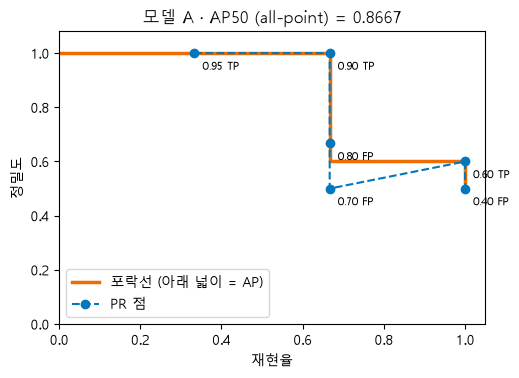

In [17]:
# 신뢰도 높은 순으로 한 박스씩 더하며 (재현율, 정밀도) 점 찍기
def pr_points(rows, n_gt):                              # 판정 → (재현율, 정밀도) 점
    tp = np.cumsum([t for _, t, _ in rows])             # 누적 TP
    return tp / n_gt, tp / np.arange(1, len(rows) + 1)  # 정답 기준 · 낸 박스 기준


# 포락선(보간): 오른쪽(재현율 같거나 큰 쪽)에서 본 최댓값
def envelope(prec):                                 # 지그재그 → 계단
    return np.maximum.accumulate(prec[::-1])[::-1]  # 뒤집기 → 누적 최대 → 뒤집기


# all-point AP: 재현율이 바뀌는 자리마다 (너비 × 포락선 높이)
def ap_all_point(rec, prec):                            # 계단 아래 넓이
    r = np.concatenate([[0.0], rec, [1.0]])             # 재현율 0 ~ 1 양 끝을 붙임
    p = envelope(np.concatenate([[0.0], prec, [0.0]]))  # 끝 높이 0 · 포락선
    return float(np.sum((r[1:] - r[:-1]) * p[1:]))      # 너비 × 높이의 합


rec_A, prec_A = pr_points(rows_A, 3)                                           # 모델 A의 점 6개
for (c, tp, _), r, p, e in zip(rows_A, rec_A, prec_A, envelope(prec_A)):       # 점마다
    print(f"{c:.2f} {'TP' if tp else 'FP'} | 재현율 {r:.3f} · 정밀도 {p:.3f}"  # 점 · 포락선 높이
          f" · 포락선 {e:.3f}")
print(f"손계산: (2/3) × 1.0 + (1/3) × 0.6 = {2 / 3 * 1.0 + 1 / 3 * 0.6:.4f}")  # 직사각형 두 개
print(f"함수  : AP = {ap_all_point(rec_A, prec_A):.4f}")                       # 함수 결과와 같은지


# PR 점 · 포락선 그림
fig, ax = plt.subplots(figsize=(5.5, 3.8))                                      # PR 그림
ax.step(np.r_[0, rec_A], np.r_[1, envelope(prec_A)], where="pre",               # 계단 = 포락선
        color="#ef6c00", lw=2.5, label="포락선 (아래 넓이 = AP)")
ax.plot(rec_A, prec_A, "o--", color=PRED_COLOR, label="PR 점")                  # 실제 점
for (c, tp, _), r, p in zip(rows_A, rec_A, prec_A):                             # 점마다 이름표
    ax.annotate(f"{c:.2f} {'TP' if tp else 'FP'}", (r, p),                      # 신뢰도 · 판정
                xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set(xlabel="재현율", ylabel="정밀도", xlim=(0, 1.05), ylim=(0, 1.08))        # 축 이름 · 범위
ax.legend(loc="lower left")                                                     # 범례는 빈 곳에
ax.set_title(f"모델 A · AP50 (all-point) = {ap_all_point(rec_A, prec_A):.4f}")  # 제목에 AP
plt.show()                                                                      # 그림 출력

**결과** · 예측 정답은 `0.8667` — 직사각형 두 개: (2/3) × 1.0 + (1/3) × 0.6

- `0.95 TP | 재현율 0.333 · 정밀도 1.000 · 포락선 1.000` — TP → 재현율이 1/3 오름
- `0.80 FP | 재현율 0.667 · 정밀도 0.667 · 포락선 0.667` — FP → 재현율 그대로, 정밀도만 하락
- `0.70 FP | 재현율 0.667 · 정밀도 0.500 · 포락선 0.600` — 포락선 = 오른쪽(0.60 TP 점)의 0.600 → 지그재그를 계단으로
- `0.60 TP | 재현율 1.000 · 정밀도 0.600 · 포락선 0.600` — 마지막 TP → 재현율 1
- `손계산: (2/3) × 1.0 + (1/3) × 0.6 = 0.8667` — 직사각형 두 개 넓이의 합
- `함수  : AP = 0.8667` — `ap_all_point` 결과가 손계산과 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">PR 점 그대로</td>
<td style="text-align: left;">FP마다 아래로 꺾이는 지그재그</td>
<td style="text-align: left;">판정 순서 확인</td>
</tr>
<tr>
<td style="text-align: left;">포락선 (보간 정밀도)</td>
<td style="text-align: left;">그 재현율 이상에서 얻을 수 있는 최고 정밀도</td>
<td style="text-align: left;">AP 계산의 높이</td>
</tr>
<tr>
<td style="text-align: left;">F1 (한 임곗값)</td>
<td style="text-align: left;">PR 곡선 위의 점 하나</td>
<td style="text-align: left;">실제로 쓸 기준 하나의 성능</td>
</tr>
<tr>
<td style="text-align: left;">AP</td>
<td style="text-align: left;">포락선 아래 전체 넓이</td>
<td style="text-align: left;">모델끼리 비교</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 점을 그대로 잇거나 둥근 곡선으로 그리면 안 됨 → 점 사이에는 실제 값이 없고, 포락선은 가로 · 세로 선만으로 된 계단

> ✅ **한 줄 정리** · AP는 신뢰도 높은 순으로 찍은 PR 점의 포락선 아래 넓이이고, 모든 정답을 FP 없이 찾을 때만 1이 된다.

**딥러닝 코드에서는**

- 모델 비교 · 체크포인트 고르기는 F1 하나보다 AP · mAP로 함 (객체탐지-2)

### 6-2. `A` AP 계산 방식과 torchmetrics 검증 · `MeanAveragePrecision()` <sub>보충 B4 · B5</sub>

> 🎯 **같은 예측인데 AP 값이 달라지는 경우는 언제이고, torchmetrics의 값은 직접 계산과 같은가?**

💡 **쉽게 말하면**

- 같은 계단이라도 **넓이를 재는 자**가 다르면 값이 조금씩 다름.
- all-point는 계단 넓이 그대로, 11-point · 101-point는 정해진 자리에서 높이를 읽어 평균.

**실행 흐름**

1. 11 · 101-point 함수
2. (신뢰도, 사진, 박스)를 torchmetrics 입력으로 변환
3. 모델 A · B를 네 방식으로 비교
4. 신뢰도 0.75로 먼저 자른 AP

**먼저 예측** · torchmetrics(COCO 방식)의 AP50은 all-point 0.8667과 같을까? — 답은 코드 실행 결과 아래에

In [18]:
from torchmetrics.detection import MeanAveragePrecision  # COCO 방식 mAP


# 11-point · 101-point: 정해진 재현율 자리에서 포락선 높이를 읽어 평균
def ap_n_point(rec, prec, n):                                              # n곳에서 읽어 평균
    env = envelope(prec)                                                   # 포락선 높이
    idx = np.searchsorted(rec, np.linspace(0, 1, n), side="left")          # 처음 닿는 점
    return float(np.mean([env[i] if i < len(env) else 0.0 for i in idx]))  # 못 닿은 자리 = 0


# {클래스 번호: (예측 목록, 정답 dict)} → torchmetrics 입력 (사진마다 dict)
def to_tm(by_class):                                                     # 목록 → torchmetrics 입력
    imgs = sorted({im for _, gt in by_class.values() for im in gt})      # 사진 이름 모음
    preds, targets = [], []                                              # 사진마다 dict 하나씩
    for im in imgs:                                                      # 사진마다
        pb, ps, pl, tb, tl = [], [], [], [], []                          # 예측 · 정답 칸
        for c, (pr, gt) in by_class.items():                             # 클래스마다
            for conf, im2, box in pr:                                    # 예측 하나씩
                if im2 == im:                                            # 이 사진의 예측만
                    pb.append(box), ps.append(conf), pl.append(c)        # 박스 · 점수 · 라벨
            tb += gt.get(im, [])                                         # 이 사진의 정답 박스
            tl += [c] * len(gt.get(im, []))                              # 정답 수만큼 라벨
        preds.append({"boxes": torch.tensor(pb).float().reshape(-1, 4),  # 비어도 (0, 4)
                      "scores": torch.tensor(ps).float(),
                      "labels": torch.tensor(pl).long()})
        targets.append({"boxes": torch.tensor(tb).float().reshape(-1, 4),  # 정답도 같은 모양
                        "labels": torch.tensor(tl).long()})
    return preds, targets                                                # update에 그대로


def tm_map(by_class, **kw):            # 채점 한 번에
    m = MeanAveragePrecision(**kw)     # 기본: COCO 방식 · 101-point
    m.warn_on_many_detections = False  # 사진당 100개 넘음 경고 끄기
    m.update(*to_tm(by_class))         # 예측 · 정답 넣기
    return m.compute()                 # 지표 dict


# 검증표: 같은 판정 · 계산 방식만 다름
rec_B, prec_B = pr_points(rows_B, 3)                                       # 모델 B의 점
for name, (r, p), pr in [("A", (rec_A, prec_A), PRED_A),                   # 두 모델 같은 표로
                         ("B", (rec_B, prec_B), PRED_B)]:
    tm = tm_map({1: (pr, GT)}, iou_thresholds=[0.5])["map"].item()         # IoU 0.5 → AP50
    p101 = ap_n_point(r, p, 101)                                           # 직접 계산한 101-point
    print(f"모델 {name} | all-point {ap_all_point(r, p):.4f} · 11-point "  # 네 방식 비교
          f"{ap_n_point(r, p, 11):.4f} · 101-point {p101:.4f} |"
          f" torchmetrics {tm:.4f} | 같음 {abs(p101 - tm) < 1e-6}")


# 신뢰도 0.75로 먼저 자르고 AP를 구하면
cut = [row for row in rows_A if row[0] >= 0.75]                   # 0.75로 먼저 자른 예측
print(f"0.75 이상만: 재현율 최대 {pr_points(cut, 3)[0][-1]:.3f}"  # 곡선이 일찍 끝남
      f" | AP {ap_all_point(*pr_points(cut, 3)):.4f}")

모델 A | all-point 0.8667 · 11-point 0.8545 · 101-point 0.8653 | torchmetrics 0.8653 | 같음 True
모델 B | all-point 0.8333 · 11-point 0.8409 · 101-point 0.8342 | torchmetrics 0.8342 | 같음 True
0.75 이상만: 재현율 최대 0.667 | AP 0.6667


**결과** · 예측 정답은 다름 — `0.8653`, 101-point 직접 계산과 같음 (COCO는 재현율 101곳에서 읽음)

- `모델 A | all-point 0.8667 · 11-point 0.8545 · 101-point 0.8653 | torchmetrics 0.8653 | 같음 True` — 같은 판정인데 읽는 자리에 따라 조금씩 다름, torchmetrics = 101-point
- `모델 B | all-point 0.8333 · 11-point 0.8409 · 101-point 0.8342 | torchmetrics 0.8342 | 같음 True` — B도 101-point와 같음, AP로는 A가 조금 높음 → 5-2에서 임곗값마다 뒤집히던 비교가 숫자 하나로 정리
- `0.75 이상만: 재현율 최대 0.667 | AP 0.6667` — 0.60 TP가 잘려 재현율 2/3에서 끝남 → 넓이 감소 (모델은 그대로)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">all-point</td>
<td style="text-align: left;">계단 넓이 그대로 (구간 너비만큼 가중)</td>
<td style="text-align: left;">PASCAL VOC 2010 이후</td>
</tr>
<tr>
<td style="text-align: left;">11-point</td>
<td style="text-align: left;">재현율 0, 0.1, …, 1.0 의 11곳 평균</td>
<td style="text-align: left;">PASCAL VOC 2007 (옛 논문과 비교)</td>
</tr>
<tr>
<td style="text-align: left;">101-point</td>
<td style="text-align: left;">재현율 0, 0.01, …, 1.0 의 101곳 평균</td>
<td style="text-align: left;">COCO · torchmetrics · ultralytics (요즘 기본)</td>
</tr>
<tr>
<td style="text-align: left;">직접 만든 평가 함수</td>
<td style="text-align: left;">규칙 일부만 구현</td>
<td style="text-align: left;">'COCO mAP'라고 부르지 않고 방식을 적음</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - AP를 구하기 전에 신뢰도 0.5 같은 화면 기준으로 먼저 자르면 곡선 뒤쪽이 사라져 AP가 낮아짐 → 평가용 예측은 낮은 점수(0.01 등)까지 모두 모음

> ✅ **한 줄 정리** · AP는 계산 방식마다 값이 조금 다르므로 방식을 함께 적고, torchmetrics는 COCO와 같은 101-point로 계산한다.

**딥러닝 코드에서는**

- `metric = MeanAveragePrecision()` → 배치마다 `metric.update(preds, targets)` → 끝에 `metric.compute()["map_50"]`

### 6-3. `A` 평가 IoU 임곗값 · AP50 · AP75 · `map_50` · `map_75` · `map` <sub>보충 B6 · Day01 D1-11</sub>

> 🎯 **평가 IoU 임곗값을 0.5에서 0.75로 올리면 AP는 어떻게 바뀌고, AP@[.5:.95]는 무엇의 평균인가?**

💡 **쉽게 말하면**

- 평가 IoU 임곗값은 **채점의 깐깐함**.
- 0.5는 "대략 그 자리", 0.75는 "딱 맞게", AP@[.5:.95]는 0.50부터 0.95까지 10단계로 채점한 점수의 평균.

**실행 흐름**

1. IoU 기준 10개마다 `judge`
2. AP (101-point)
3. 0.5 · 0.75 · 평균
4. torchmetrics 기본 지표와 대조

**먼저 예측** · IoU 0.53으로 TP였던 0.60 박스는 기준 0.75에서 어떻게 될까? — 답은 코드 실행 결과 아래에

In [19]:
# 평가 IoU 임곗값 0.50 ~ 0.95 (0.05 간격 10개)마다 AP
steps = np.round(np.arange(0.50, 0.96, 0.05), 2)                        # 0.50 ~ 0.95 열 개
aps = {}                                                                # 기준 → AP
for t in steps:                                                         # 기준마다 다시 채점
    rows, _ = judge(PRED_A, GT, iou_thr=t)                              # 평가 IoU 기준만 바꿈
    aps[t] = ap_n_point(*pr_points(rows, 3), 101)                       # COCO와 같은 101-point
print("TP 박스들의 IoU:", [round(v, 2) for _, tp, v in rows_A if tp])   # 기준에 걸리는 값
print("임곗값별 AP:", {float(t): round(v, 4) for t, v in aps.items()})  # 기준별 AP


# 검증표: 직접 계산 vs torchmetrics 기본 설정
res = tm_map({1: (PRED_A, GT)})                               # 기본 설정 = 열 개 기준
mine = {"map_50": aps[0.5], "map_75": aps[0.75],              # 직접 계산 세 값
        "map": float(np.mean(list(aps.values())))}
for k, v in mine.items():                                     # 지표마다 대조
    tm = res[k].item()                                        # 라이브러리 값
    print(f"{k:6s} | 직접 {v:.4f} | torchmetrics {tm:.4f} |"  # 같은지
          f" 같음 {abs(v - tm) < 1e-6}")

TP 박스들의 IoU: [0.89, 0.88, 0.53]
임곗값별 AP: {0.5: 0.8653, 0.55: 0.6634, 0.6: 0.6634, 0.65: 0.6634, 0.7: 0.6634, 0.75: 0.6634, 0.8: 0.6634, 0.85: 0.6634, 0.9: 0.0, 0.95: 0.0}
map_50 | 직접 0.8653 | torchmetrics 0.8653 | 같음 True
map_75 | 직접 0.6634 | torchmetrics 0.6634 | 같음 True
map    | 직접 0.5509 | torchmetrics 0.5509 | 같음 True


**결과** · 예측 정답은 `FP` — 기준 0.55부터 FP가 되어 AP가 0.8653 → 0.6634로 떨어짐

- `TP 박스들의 IoU: [0.89, 0.88, 0.53]` — 기준 0.55부터 0.53 박스가 빠지고, 0.9부터 셋 다 빠짐
- `임곗값별 AP: {0.5: 0.8653, 0.55: 0.6634` — 0.55 ~ 0.85는 0.6634, 0.9 · 0.95는 0
- `map_50 | 직접 0.8653 | torchmetrics 0.8653 | 같음 True` — AP50 = 평가 IoU 0.5
- `map_75 | 직접 0.6634 | torchmetrics 0.6634 | 같음 True` — AP75 = 0.75, 0.53 박스가 FP로
- `map    | 직접 0.5509 | torchmetrics 0.5509 | 같음 True` — 0.8653 + 0.6634 × 7 = 5.5091 → 열 개로 나눠 0.5509 = AP@[.5:.95]

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">AP50</td>
<td style="text-align: left;">평가 IoU 0.5 · 대략 그 자리면 맞음</td>
<td style="text-align: left;">VOC 방식 · 위치가 대략이면 충분할 때</td>
</tr>
<tr>
<td style="text-align: left;">AP75</td>
<td style="text-align: left;">평가 IoU 0.75 · 딱 맞아야 맞음</td>
<td style="text-align: left;">박스 위치가 중요할 때</td>
</tr>
<tr>
<td style="text-align: left;">AP@[.5:.95]</td>
<td style="text-align: left;">0.50 ~ 0.95 열 개의 평균 · 가장 엄격</td>
<td style="text-align: left;">COCO 대표 지표 · 모델 비교</td>
</tr>
<tr>
<td style="text-align: left;">신뢰도 임곗값 (0.5 등)</td>
<td style="text-align: left;">예측 하나의 점수 기준 → 어떤 박스까지 볼지</td>
<td style="text-align: left;">결과 거르기 (4-1)</td>
</tr>
<tr>
<td style="text-align: left;">NMS 기준 (0.45)</td>
<td style="text-align: left;">예측 ↔ 예측 IoU</td>
<td style="text-align: left;">겹친 후보 정리 (4-2)</td>
</tr>
<tr>
<td style="text-align: left;">평가 IoU 임곗값 (0.5)</td>
<td style="text-align: left;">예측 ↔ 정답 IoU → 얼마나 맞아야 TP인지</td>
<td style="text-align: left;">채점 (5-1 · 6-3)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 논문 · 대회의 'mAP'가 AP50인지 AP@[.5:.95]인지 먼저 확인 → 같은 모델도 0.87과 0.55처럼 크게 다르게 보임

> ✅ **한 줄 정리** · 평가 IoU 임곗값을 올리면 위치가 덜 맞은 TP가 FP로 바뀌어 AP가 내려가고, AP@[.5:.95]는 0.50 ~ 0.95 열 개 AP의 평균이다.

**딥러닝 코드에서는**

- `metric.compute()` 한 번에 `map`(= @[.5:.95]) · `map_50` · `map_75` · `map_small` 등이 모두 나옴

### 6-4. `A` mAP와 평균 IoU 반례 · `class_metrics=True` <sub>보충 B7 · B8</sub>

> 🎯 **mAP는 AP와 무엇이 다르고, 맞힌 박스의 평균 IoU가 높으면 좋은 모델이라고 할 수 있는가?**

💡 **쉽게 말하면**

- AP는 **과목 하나의 점수**, mAP는 **과목 평균**.
- 평균 IoU는 "맞힌 문제를 얼마나 깔끔하게 풀었나"만 보고 안 푼 문제(FN)는 세지 않는 점수라, 한 문제만 완벽히 풀어도 높게 나옴.

**실행 흐름**

1. 개 얼굴 클래스 추가
2. 클래스별 AP
3. 평균 = mAP
4. torchmetrics 클래스별 결과 대조
5. 모델 C (1개 딱 맞음) vs D (3개 적당히)의 평균 IoU · AP50

**먼저 예측** · 평균 IoU 0.98인 모델 C와 0.67인 모델 D 중 AP50이 높은 쪽은? — 답은 코드 실행 결과 아래에

In [20]:
# 개 얼굴 클래스 추가: 정답 2개 · 예측 2개 (둘 다 잘 맞음)
GT_DOG = {"사진3": [[20, 20, 80, 80]], "사진4": [[50, 40, 110, 100]]}  # 두 번째 클래스 정답
PRED_DOG = [(0.9, "사진3", [22, 18, 82, 80]),                          # 둘 다 잘 맞는 예측
            (0.7, "사진4", [48, 42, 108, 104])]


# mAP = 클래스별 AP의 평균
ap_cat = ap_n_point(*pr_points(judge(PRED_A, GT)[0], 3), 101)        # 고양이 AP50
ap_dog = ap_n_point(*pr_points(judge(PRED_DOG, GT_DOG)[0], 2), 101)  # 개 AP50
print(f"고양이 AP50 {ap_cat:.4f} · 개 AP50 {ap_dog:.4f}"             # 평균 = mAP50
      f" → mAP50 = {(ap_cat + ap_dog) / 2:.4f}")
res = tm_map({1: (PRED_A, GT), 2: (PRED_DOG, GT_DOG)},               # 두 클래스 함께
             iou_thresholds=[0.5], class_metrics=True)
print("torchmetrics: 클래스별",                                      # 클래스별 · 평균 대조
      [round(v, 4) for v in res["map_per_class"].tolist()],
      "| mAP50", round(res["map"].item(), 4))


# 반례: 평균 IoU가 높으면 좋은 모델인가?
PRED_C = [(0.90, "사진1", [10, 10, 60, 59])]                            # 1개만 · 딱 맞음
PRED_D = [(0.90, "사진1", [16, 14, 66, 62]),                            # 3개 · 적당히 맞음
          (0.85, "사진1", [106, 25, 156, 75]),
          (0.80, "사진2", [37, 36, 97, 96])]                            # 3개 · 적당히 맞음
for name, pr in [("모델 C", PRED_C), ("모델 D", PRED_D)]:               # 두 모델
    rows, fn = judge(pr, GT)                                            # 같은 규칙 채점
    ious = [v for _, tp, v in rows if tp]                               # 맞힌 박스의 IoU만
    print(f"{name}: 맞힘 {len(ious)}개 · 평균 IoU {np.mean(ious):.3f}"  # 평균 IoU vs AP50
          f" · 놓침 {fn}개 · AP50 {ap_all_point(*pr_points(rows, 3)):.3f}")

고양이 AP50 0.8653 · 개 AP50 1.0000 → mAP50 = 0.9327
torchmetrics: 클래스별 [0.8653, 1.0] | mAP50 0.9327
모델 C: 맞힘 1개 · 평균 IoU 0.980 · 놓침 2개 · AP50 0.333
모델 D: 맞힘 3개 · 평균 IoU 0.673 · 놓침 0개 · AP50 1.000


**결과** · 예측 정답은 모델 D (1.000 > 0.333) — C는 정답 3개 중 1개만 찾음

- `고양이 AP50 0.8653 · 개 AP50 1.0000 → mAP50 = 0.9327` — 0.8653 + 1.0 = 1.8653 → 클래스 2개로 나눔
- `torchmetrics: 클래스별 [0.8653, 1.0] | mAP50 0.9327` — `class_metrics=True` → 클래스별 AP와 평균이 직접 계산과 같음
- `모델 C: 맞힘 1개 · 평균 IoU 0.980 · 놓침 2개 · AP50 0.333` — 평균 IoU는 높지만 놓친 2개가 반영 안 됨
- `모델 D: 맞힘 3개 · 평균 IoU 0.673 · 놓침 0개 · AP50 1.000` — 평균 IoU는 낮지만 셋 다 찾음 → AP50 최고

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">AP</td>
<td style="text-align: left;">클래스 하나의 PR 넓이</td>
<td style="text-align: left;">클래스별 약점 찾기</td>
</tr>
<tr>
<td style="text-align: left;">mAP</td>
<td style="text-align: left;">클래스별 AP의 평균</td>
<td style="text-align: left;">모델 전체를 숫자 하나로</td>
</tr>
<tr>
<td style="text-align: left;">맞힌 박스 평균 IoU</td>
<td style="text-align: left;">TP 박스만 · FN · FP 무시</td>
<td style="text-align: left;">박스가 얼마나 딱 맞는지 진단</td>
</tr>
<tr>
<td style="text-align: left;">mAP vs 평균 IoU</td>
<td style="text-align: left;">놓침 · 오탐 반영 vs 미반영</td>
<td style="text-align: left;">모델 선택은 mAP</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 평균 IoU에는 FN(놓침)과 FP(헛짚음)가 들어가지 않음 → mAP를 대신할 수 없고, 쓸 때는 어떤 박스만 모았는지 함께 적음

> ✅ **한 줄 정리** · mAP는 클래스별 AP의 평균이고, 맞힌 박스의 평균 IoU는 놓친 정답을 세지 않아 높아도 나쁜 모델일 수 있다.

**딥러닝 코드에서는**

- 클래스 불균형(개 2498 · 고양이 1189, 2-4)이 있으면 mAP와 함께 `map_per_class`를 보고 약한 클래스를 찾음

---
## 7. 종합 실습 · 사전학습 SSD 예측을 직접 채점하기

> **이 장의 흐름**
>
> - 1 ~ 6장을 실제 사진에 한 번에 사용
> - Day01 D1-11의 사진 8장 채점을 24장으로 늘림
> - NMS 전 · 후 예측을 각각 채점 → 직접 계산한 AP와 torchmetrics AP가 같은지 확인

<img src="images/od1_flow.png" alt="IoU → NMS → 짝짓기 → AP 한 장 흐름" width="762">

**파이프라인 위치** · ① 정답 읽기(2장) → ④ 예측 · NMS(1 · 4장) → ⑥ 짝짓기 · AP(3 · 5 · 6장)

> 🎯 **COCO로 학습된 SSD를 우리 정답(머리 박스)으로 채점하면 몇 점이고, 직접 계산한 AP는 라이브러리 값과 같은가?**

💡 **쉽게 말하면**

- 다른 학교 시험(COCO: 몸 전체에 박스)을 잘 보던 학생에게 **우리 학교 시험지**(머리에 박스)를 풀게 함
- 직접 채점한 점수와 채점 기계(torchmetrics) 점수를 맞춰 봄

**실행 흐름**

1. XML 있는 사진 중 고양이 · 개 각 12장, 클래스별 정답 dict (2-4 · 2-5)
2. NMS 전(`raw`) · 후(`detector`) 예측 모으기, COCO cat · dog → 우리 번호 1 · 2 (1-2 · 4-3)
3. 클래스마다 짝짓기 → AP50 직접 계산 vs torchmetrics (5-1 · 6-2)
4. 엄격한 기준: mAP75 · mAP@[.5:.95] (6-3)
5. 실제로 쓸 신뢰도 0.5의 정밀도 · 재현율 · F1 (5-2)
6. 사진 4장으로 낮은 이유 확인 (3-2)

**먼저 예측** · NMS 전 예측으로 채점하면 NMS 후보다 mAP50이 높을까, 낮을까? — 답은 코드 실행 결과 아래에

In [21]:
# 1) 채점용 사진: XML이 있는 사진 중 고양이 · 개 각 12장 (seed 0)
rng = np.random.default_rng(0)                                     # seed 0 → 매번 같은 사진
cats = [s for s in records if s[0].isupper()]                      # 대문자 = 고양이 품종
dogs = [s for s in records if s[0].islower()]                      # 소문자 = 개 품종
photos = (sorted(rng.choice(cats, 12, replace=False).tolist())     # 고양이 12 + 개 12
          + sorted(rng.choice(dogs, 12, replace=False).tolist()))
gt_all = {c: {s: [b for b, n in zip(records[s][2], records[s][3])  # 클래스별 정답 dict
                  if NAME_TO_LABEL[n] == c] for s in photos}
          for c in (1, 2)}                                         # 클래스 → 사진 → 박스들
print("사진", len(photos), "장 | 정답 고양이",                     # 정답 수 확인
      sum(map(len, gt_all[1].values())), "개 · 개",
      sum(map(len, gt_all[2].values())), "개")


# 2) 예측 모으기: COCO cat · dog → 우리 번호, 사진 · 클래스마다 점수 상위 MAX_DET개
COCO_TO_OURS = {COCO.index("cat"): 1, COCO.index("dog"): 2}  # COCO 번호 → 우리 번호
MAX_DET = 100  # COCO 평가의 사진당 최대 검출 수와 같게


def collect(model):                                                  # 모델 하나의 예측 모으기
    preds = {1: [], 2: []}                                           # 클래스별 목록
    for s in photos:                                                 # 사진마다
        o = run(model, load_image(s))                                # 예측
        for c_coco, c in COCO_TO_OURS.items():                       # cat · dog만
            m = o["labels"] == c_coco                                # 그 클래스 줄만
            top = o["scores"][m].argsort(descending=True)[:MAX_DET]  # 점수 상위 100개
            preds[c] += [(v, s, b) for v, b in                       # (신뢰도, 사진, 박스) 형식
                         zip(o["scores"][m][top].tolist(),
                             o["boxes"][m][top].tolist())]
    return preds                                                     # judge · to_tm이 받는 형식


pred_before, pred_after = collect(raw), collect(detector)            # NMS 전 · 후
for name, pr in (("NMS 전", pred_before), ("NMS 후", pred_after)):   # 두 예측 비교
    print(f"{name}: 예측 고양이 {len(pr[1])}개 · 개 {len(pr[2])}개"  # 예측 수
          f" (사진 · 클래스마다 최대 {MAX_DET}개)")

사진 24 장 | 정답 고양이 12 개 · 개 12 개


NMS 전: 예측 고양이 1217개 · 개 1099개 (사진 · 클래스마다 최대 100개)
NMS 후: 예측 고양이 204개 · 개 172개 (사진 · 클래스마다 최대 100개)


In [22]:
# 3) 짝짓기 → AP50: 직접 계산 vs torchmetrics (NMS 전 · 후)
summary = {}                                                              # NMS 전 · 후 mAP50
for name, pr in (("NMS 전", pred_before), ("NMS 후", pred_after)):        # 두 예측마다
    res = tm_map({c: (pr[c], gt_all[c]) for c in (1, 2)},                 # 라이브러리 채점
                 iou_thresholds=[0.5], class_metrics=True)
    mine = []                                                             # 직접 계산 AP
    for c, tm in zip((1, 2), res["map_per_class"].tolist()):              # 클래스마다 대조
        rows, fn = judge(pr[c], gt_all[c])                                # 직접 짝짓기
        n_gt = sum(map(len, gt_all[c].values()))                          # 그 클래스 정답 수
        mine.append(ap_n_point(*pr_points(rows, n_gt), 101))              # COCO와 같은 101-point
        n_tp = sum(tp for _, tp, _ in rows)                               # 맞힌 수
        print(f"{name} {['', 'cat', 'dog'][c]} | TP {n_tp:2d} · FN {fn}"  # 두 AP 비교
              f" | 직접 AP50 {mine[-1]:.4f} | torchmetrics {tm:.4f} |"
              f" 같음 {abs(mine[-1] - tm) < 1e-6}")
    summary[name] = (float(np.mean(mine)), res["map"].item())             # 평균 = mAP50
for name, (m, tm) in summary.items():                                     # mAP 비교
    print(f"{name} mAP50: 직접 {m:.4f} | torchmetrics {tm:.4f}")          # 직접 = 라이브러리


# 4) 기준을 엄격하게: COCO 기본 지표 (NMS 후)
res = tm_map({c: (pred_after[c], gt_all[c]) for c in (1, 2)})  # 기본 = 열 개 기준
print("NMS 후 | mAP50", round(res["map_50"].item(), 4),        # 엄격할수록 낮아짐
      "| mAP75", round(res["map_75"].item(), 4),
      "| mAP@[.5:.95]", round(res["map"].item(), 4))


# 5) 실제로 쓸 신뢰도 0.5에서의 정밀도 · 재현율 (NMS 후 · 두 클래스 합)
rows_all = sorted(judge(pred_after[1], gt_all[1])[0]             # 두 클래스 판정을 합침
                  + judge(pred_after[2], gt_all[2])[0], key=lambda r: -r[0])
n_all = sum(len(b) for c in (1, 2) for b in gt_all[c].values())  # 전체 정답 수
tp, fp, fn, p, r, f1 = prf(rows_all, 0.5, n_gt=n_all)            # 실제로 쓸 기준 0.5
print(f"신뢰도 0.5 | TP {tp} · FP {fp} · FN {fn}"                # 개수 · 지표
      f" | 정밀도 {p:.3f} · 재현율 {r:.3f} · F1 {f1:.3f}")

NMS 전 cat | TP 12 · FN 0 | 직접 AP50 0.0327 | torchmetrics 0.0327 | 같음 True
NMS 전 dog | TP 11 · FN 1 | 직접 AP50 0.1666 | torchmetrics 0.1666 | 같음 True
NMS 후 cat | TP 12 · FN 0 | 직접 AP50 0.1291 | torchmetrics 0.1291 | 같음 True
NMS 후 dog | TP 10 · FN 2 | 직접 AP50 0.3519 | torchmetrics 0.3519 | 같음 True
NMS 전 mAP50: 직접 0.0996 | torchmetrics 0.0996
NMS 후 mAP50: 직접 0.2405 | torchmetrics 0.2405
NMS 후 | mAP50 0.2405 | mAP75 0.0329 | mAP@[.5:.95] 0.0906
신뢰도 0.5 | TP 6 · FP 16 · FN 18 | 정밀도 0.273 · 재현율 0.250 · F1 0.261


Abyssinian_117         예측 1개 | 정답과 최대 IoU 0.12
Maine_Coon_111         예측 1개 | 정답과 최대 IoU 0.37
american_bulldog_105   예측 1개 | 정답과 최대 IoU 0.40
leonberger_172         예측 0개 | 정답과 최대 IoU 0.00


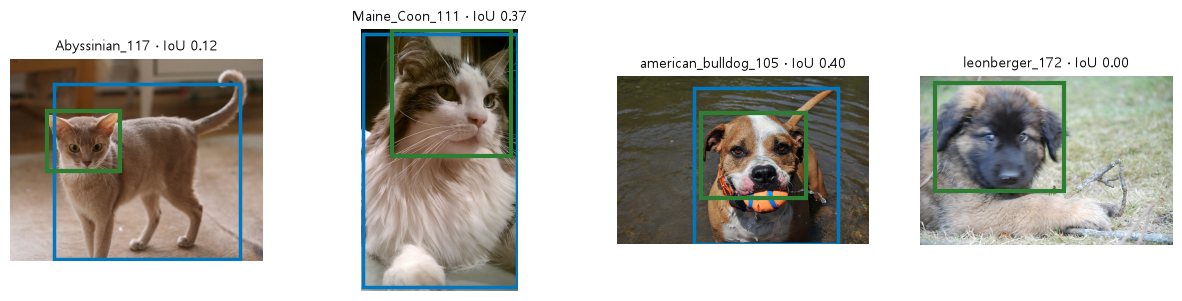

In [23]:
# 6) 왜 낮은가? 사진 4장: 정답(머리) vs 신뢰도 0.5 넘는 예측
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))                    # 사진 4장 나란히
for s, ax in zip(photos[::6], axes):                                 # 6장 간격으로 4장
    c = NAME_TO_LABEL[records[s][3][0]]                              # 이 사진의 클래스
    pb = [b for v, im, b in pred_after[c] if im == s and v > 0.5]    # 0.5 넘는 예측만
    best = max([iou_hand(b, g) for b in pb for g in gt_all[c][s]],   # 가장 많이 겹친 값
               default=0.0)
    print(f"{s:22s} 예측 {len(pb)}개 | 정답과 최대 IoU {best:.2f}")  # 낮은 이유 확인
    show(load_image(s), gt=gt_all[c][s], pred=pb,                    # 초록 = 머리 · 파랑 = 몸
         title=f"{s} · IoU {best:.2f}", ax=ax)
plt.show()                                                           # 그림 출력

**결과** · 예측 정답은 낮음 — NMS 전 `0.0996` vs NMS 후 `0.2405`, 같은 물체에 겹친 중복 박스가 모두 FP가 되기 때문

- `사진 24 장 | 정답 고양이 12 개 · 개 12 개` — XML 있는 사진에서 seed 0으로 고른 채점용 사진
- `NMS 전: 예측 고양이 1217개 · 개 1099개` — 사진 · 클래스마다 점수 상위 100개까지 (COCO 사진당 최대 검출 수와 같게)
- `NMS 후: 예측 고양이 204개 · 개 172개` — 모델 출력 중 cat · dog 줄만
- `NMS 전 cat | TP 12 · FN 0 | 직접 AP50 0.0327 | torchmetrics 0.0327 | 같음 True` — 정답은 다 찾지만 중복 FP가 많음
- `NMS 후 cat | TP 12 · FN 0 | 직접 AP50 0.1291 | torchmetrics 0.1291 | 같음 True` — 중복이 사라져 AP가 오름
- `NMS 후 dog | TP 10 · FN 2 | 직접 AP50 0.3519 | torchmetrics 0.3519 | 같음 True` — 개 얼굴이 고양이보다 높음
- `NMS 전 mAP50: 직접 0.0996 | torchmetrics 0.0996` — NMS 전 예측으로 채점 → 중복이 모두 FP
- `NMS 후 mAP50: 직접 0.2405 | torchmetrics 0.2405` — 직접 계산과 라이브러리가 소수 넷째 자리까지 같음
- `NMS 후 | mAP50 0.2405 | mAP75 0.0329 | mAP@[.5:.95] 0.0906` — 기준이 엄격할수록 급락 → 박스가 머리에 딱 맞지 않음
- `신뢰도 0.5 | TP 6 · FP 16 · FN 18 | 정밀도 0.273 · 재현율 0.250 · F1 0.261` — 실제로 쓸 기준에서는 24개 중 6개만 맞힘
- `Abyssinian_117         예측 1개 | 정답과 최대 IoU 0.12` — 고양이 몸 전체 박스 → 머리 정답과 거의 안 겹침
- `american_bulldog_105   예측 1개 | 정답과 최대 IoU 0.40` — 가장 많이 겹치지만 평가 IoU 0.5에 못 미침 → FP
- `leonberger_172         예측 0개 | 정답과 최대 IoU 0.00` — 신뢰도 0.5 넘는 dog 박스가 없음 (놓침)

**해석**

- COCO SSD는 고양이 · 개를 잘 찾지만(신뢰도 0.9 이상) **몸 전체**에 박스를 치도록 배웠음
- 우리 정답은 **머리** 박스 → 정답의 정의가 달라 mAP50이 0.24에 그침
- 모델이 나쁜 게 아니라 시험 범위가 다른 것 → 우리 정답으로 다시 학습해야 함 (**객체탐지-2**)
- NMS 전 예측으로 채점하면 0.0996으로 더 낮아짐 → 채점에는 NMS 후 출력을 씀

**결과를 적는 한 문장** (보충 B9 형식)

- 조건: trainval 중 XML 있는 사진 24장(seed 0) · 평가 IoU 0.5 · 모델 안 신뢰도 하한 0.01로 모은 NMS 후 예측
- 계산: torchmetrics(101-point) · 고양이 얼굴 정답 12개 · 개 얼굴 정답 12개
- 결과: 고양이 AP50 0.1291 · 개 AP50 0.3519 · mAP50 0.2405 (신뢰도 0.5에서 정밀도 0.273 · 재현율 0.250)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">직접 만든 짝짓기 + 101-point</td>
<td style="text-align: left;">규칙을 한 줄씩 확인 가능</td>
<td style="text-align: left;">원리 검증 · 오류 분석 (어느 박스가 FP인지)</td>
</tr>
<tr>
<td style="text-align: left;">torchmetrics <code>MeanAveragePrecision</code></td>
<td style="text-align: left;">COCO 규칙 전체 (크기별 · 최대 검출 수)</td>
<td style="text-align: left;">실제 평가 · 보고 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">NMS 전 예측으로 채점</td>
<td style="text-align: left;">중복 박스가 FP → AP 낮음</td>
<td style="text-align: left;">쓰지 않음 (NMS 효과 확인용)</td>
</tr>
<tr>
<td style="text-align: left;">NMS 후 예측으로 채점</td>
<td style="text-align: left;">물체마다 대체로 박스 하나</td>
<td style="text-align: left;">평가 · 보고 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">mAP50 vs mAP@[.5:.95]</td>
<td style="text-align: left;">대략 맞으면 정답 vs 10단계 엄격 평균</td>
<td style="text-align: left;">둘 다 적고 어느 것인지 밝힘</td>
</tr>
<tr>
<td style="text-align: left;">mAP vs 신뢰도 0.5의 F1</td>
<td style="text-align: left;">모든 기준 vs 실제로 쓸 기준 하나</td>
<td style="text-align: left;">모델 비교는 mAP, 서비스 판단은 F1</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 정답의 정의(머리 vs 몸 전체)가 다른 모델을 그대로 채점하면 낮은 점수가 모델 탓처럼 보임
> - 채점 전에 모델이 배운 정답과 우리 정답이 같은지 먼저 확인

> ✅ **한 줄 정리** · NMS 후 예측을 짝지어 계산한 AP는 torchmetrics와 같고, 평가 조건(IoU · 신뢰도 하한 · 계산 방식 · 정답 수)을 함께 적어야 재현된다.

**딥러닝 코드에서는**

- 검증 루프에서 `metric.update(model(images), targets)`
- epoch 끝에 `metric.compute()["map_50"]`으로 체크포인트를 고름 (객체탐지-2)

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 출력 · 정답 형식</td>
<td style="text-align: left;">SSD 출력 boxes (200, 4) · 정답 target <code>{boxes float32 [N, 4], labels int64 [N]}</code></td>
<td style="text-align: left;">1-2 · 2-5</td>
</tr>
<tr>
<td style="text-align: left;">2. 박스 표기 · 변환</td>
<td style="text-align: left;"><code>[241, 31, 310, 102]</code> → xywh 너비 69 · 높이 71, 뒤집으면 <code>[90, 31, 159, 102]</code></td>
<td style="text-align: left;">2-2 · 2-3</td>
</tr>
<tr>
<td style="text-align: left;">3. IoU · NMS</td>
<td style="text-align: left;">50 밀면 IoU 0.3333, 후보 6개에 NMS(0.5) → <code>[0, 5]</code></td>
<td style="text-align: left;">3-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">4. 짝짓기 · 정밀도 · 재현율</td>
<td style="text-align: left;">0.80 박스는 IoU 0.85여도 중복 FP, 신뢰도 0.5에서 F1 0.750</td>
<td style="text-align: left;">5-1 · 5-2</td>
</tr>
<tr>
<td style="text-align: left;">5. AP · mAP</td>
<td style="text-align: left;">손계산 0.8667 · 101-point 0.8653 = torchmetrics, 24장 mAP50 0.2405</td>
<td style="text-align: left;">6-1 · 6-2 · 7</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">분류 vs 탐지</td>
<td style="text-align: left;">분류 = 이름 하나, 탐지 = 박스 N개 + 이름 + 신뢰도</td>
<td style="text-align: left;"><code>model([img])[0]["boxes"]</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">박스 표기</td>
<td style="text-align: left;">torchvision은 xyxy, 다른 형식은 <code>box_convert</code></td>
<td style="text-align: left;"><code>box_convert(b, "xywh", "xyxy")</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">XML 읽기</td>
<td style="text-align: left;"><code>iter("object")</code>로 물체마다 name · bndbox</td>
<td style="text-align: left;"><code>read_voc(stem)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">크기 · 뒤집기</td>
<td style="text-align: left;">x · y 배율 따로, 뒤집으면 두 변 맞바꿈</td>
<td style="text-align: left;"><code>v2.RandomHorizontalFlip()(img, target)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">target 약속</td>
<td style="text-align: left;">boxes float32 [N, 4] · labels int64 [N] · 0 = 배경</td>
<td style="text-align: left;"><code>return image, target</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">IoU</td>
<td style="text-align: left;">겹친 넓이 ÷ 합친 넓이, 작은 물체일수록 민감</td>
<td style="text-align: left;"><code>box_iou(pred, gt)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">신뢰도 임곗값</td>
<td style="text-align: left;">화면 기준, AP 계산 전에는 자르지 않음</td>
<td style="text-align: left;"><code>out["scores"] &gt; 0.5</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">NMS</td>
<td style="text-align: left;">1등 남기고 많이 겹친 후보 지우기, 클래스별</td>
<td style="text-align: left;"><code>batched_nms(b, s, l, 0.45)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">짝짓기</td>
<td style="text-align: left;">신뢰도 순 · 짝 없는 정답 · IoU ≥ 기준 → TP</td>
<td style="text-align: left;">torchmetrics 안에서 실행</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">정밀도 · 재현율</td>
<td style="text-align: left;">분모 = 낸 박스 수 · 정답 수, TN 없음</td>
<td style="text-align: left;">실제로 쓸 기준 하나에서</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">AP</td>
<td style="text-align: left;">포락선 아래 넓이, 계산 방식 적기</td>
<td style="text-align: left;"><code>metric.compute()["map_50"]</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">AP50 · AP75 · AP@[.5:.95]</td>
<td style="text-align: left;">평가 IoU 기준이 엄격해질수록 낮아짐</td>
<td style="text-align: left;"><code>map_50</code> · <code>map_75</code> · <code>map</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">mAP</td>
<td style="text-align: left;">클래스별 AP 평균 + 클래스별 AP 함께</td>
<td style="text-align: left;"><code>class_metrics=True</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">데이터 점검</td>
<td style="text-align: left;">목록 · XML 유무 · 박스 범위 · 클래스 개수</td>
<td style="text-align: left;">학습 전 1회</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">평균 IoU</td>
<td style="text-align: left;">맞힌 박스만 평균 → mAP를 대신 못 함</td>
<td style="text-align: left;">진단용</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">분류 모델로는 왜 여러 물체의 위치를 알 수 없는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">탐지 모델의 출력 세 가지는 무엇이고 모양은?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">xyxy · xywh · cxcywh는 각각 무엇을 적은 것인가?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">좌우로 뒤집은 사진의 박스는 어떻게 계산하는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-5</td>
<td style="text-align: left;">탐지 한 샘플의 target 딕셔너리 약속은?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">IoU는 어떻게 계산하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">신뢰도 0.99인데 IoU가 낮을 수 있는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">NMS는 어떤 순서로 동작하고, <code>nms</code>와 <code>batched_nms</code>는 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">4-3</td>
<td style="text-align: left;">NMS 전 후보로 채점하면 왜 AP가 떨어지는가?</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">이미 짝이 있는 정답과 많이 겹친 예측은 TP인가, FP인가?</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">정밀도와 재현율의 분모는 각각 무엇인가?</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">AP는 무엇의 넓이인가?</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">AP를 구하기 전에 신뢰도 0.5로 먼저 자르면 어떻게 되는가?</td>
</tr>
<tr>
<td style="text-align: left;">6-3</td>
<td style="text-align: left;">신뢰도 임곗값 · NMS 기준 · 평가 IoU 임곗값은 각각 무엇과 무엇을 비교하는가?</td>
</tr>
<tr>
<td style="text-align: left;">6-4</td>
<td style="text-align: left;">평균 IoU가 높아도 나쁜 모델일 수 있는 이유는?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

손계산을 먼저 적고, 라이브러리로 확인. 아래 빈 셀에 직접 작성 후 실행.

1. xyxy 박스 `[50, 40, 150, 120]`을 xywh · cxcywh로 바꾸기 (`box_convert`로 확인)
2. 정답 `[0, 0, 100, 100]` · 예측 `[50, 50, 150, 150]`의 IoU를 손계산하고 `box_iou`로 확인
3. 너비 400 사진에서 박스 `[30, 10, 130, 90]`을 좌우로 뒤집은 박스
4. 후보 `[[0, 0, 10, 10], [1, 1, 11, 11], [20, 20, 30, 30]]` · 점수 `[0.9, 0.8, 0.7]`에 NMS(0.5)를 하면 남는 번호
5. 신뢰도 순 판정이 TP · FP · TP · FP이고 정답이 2개일 때 재현율 · 포락선 · all-point AP

In [24]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 정답 `[0, 0, 100, 100]` · 예측 `[0, 0, 100, 50]`의 IoU를 손으로 구하고, 평가 IoU 0.5 · 0.55에서 TP인지 판정
2. 5-1의 모델 A에서 0.60 박스를 빼면 all-point AP는? (재현율이 어디서 끝나는지 먼저)
3. 6-3의 평가 IoU 기준을 0.8로 하면 AP는? TP 박스들의 IoU `[0.89, 0.88, 0.53]`을 보고 예측 → 실행

In [25]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">사진 전체에 클래스 확률 하나만 내고 위치 칸이 없음. 창문을 옮기며 분류하면 수천 번 계산이 필요</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;"><code>boxes</code> [N, 4] xyxy · <code>scores</code> [N] 높은 순 · <code>labels</code> [N] 클래스 번호, 사진 목록을 넣고 사진마다 dict</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">두 모서리 · 왼쪽 위 + 너비 높이 · 가운데 + 너비 높이</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;"><code>[W - x2, y1, W - x1, y2]</code> (W - x 후 두 변 맞바꿈), y는 그대로</td>
</tr>
<tr>
<td style="text-align: left;">2-5</td>
<td style="text-align: left;"><code>{"boxes": float32 [N, 4] xyxy, "labels": int64 [N]}</code>, 0은 배경이라 클래스는 1부터</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">겹친 넓이 ÷ (두 넓이의 합 - 겹친 넓이), 겹친 가로 · 세로가 음수면 0</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">신뢰도는 모델의 확신, IoU는 정답과의 겹침. 정답 정의(머리 vs 몸)가 다르면 확신이 높아도 겹침이 작음</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">점수 1등을 남기고 1등과 IoU가 기준을 넘는 후보를 지우기를 반복. <code>batched_nms</code>는 같은 클래스끼리만 비교</td>
</tr>
<tr>
<td style="text-align: left;">4-3</td>
<td style="text-align: left;">같은 물체에 겹친 중복 박스가 정답 하나와만 짝지어지고 나머지는 모두 FP가 되어 정밀도가 떨어짐</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">FP (중복). 정답 하나에는 예측 하나만 짝</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">정밀도는 낸 박스 수(TP + FP), 재현율은 정답 수(TP + FN)</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">신뢰도 높은 순으로 찍은 PR 점의 포락선(오른쪽에서 본 최고 정밀도) 아래 넓이</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">곡선 뒤쪽(낮은 점수의 TP)이 사라져 재현율이 일찍 끝나고 AP가 낮아짐</td>
</tr>
<tr>
<td style="text-align: left;">6-3</td>
<td style="text-align: left;">예측 점수 하나 · 예측 ↔ 예측 IoU · 예측 ↔ 정답 IoU</td>
</tr>
<tr>
<td style="text-align: left;">6-4</td>
<td style="text-align: left;">맞힌 박스만 평균해 놓친 정답(FN)과 헛짚은 박스(FP)가 반영되지 않음</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. xywh = 왼쪽 위 + 너비 · 높이, cxcywh = 가운데 + 너비 · 높이
b = torch.tensor([[50., 40., 150., 120.]])
xywh = box_convert(b, "xyxy", "xywh")
cxcywh = box_convert(b, "xyxy", "cxcywh")
print(xywh.tolist())  # [[50.0, 40.0, 100.0, 80.0]]
print(cxcywh.tolist())  # [[100.0, 80.0, 100.0, 80.0]]

# 2. 겹친 50 × 50 = 2500, 합친 10000 + 10000 - 2500 = 17500
gt = torch.tensor([[0., 0., 100., 100.]])
pred = torch.tensor([[50., 50., 150., 150.]])
mine = 2500 / 17500
print(round(mine, 4), round(box_iou(gt, pred).item(), 4))  # 0.1429 0.1429

# 3. W - x 후 두 변 맞바꿈, y는 그대로
W, (x1, y1, x2, y2) = 400, (30, 10, 130, 90)
print([W - x2, y1, W - x1, y2])  # [270, 10, 370, 90]

# 4. 0번 · 1번 IoU = 81 ÷ 119 ≈ 0.68 > 0.5 → 1번 지움, 2번은 안 겹침
cand = torch.tensor([[0., 0., 10., 10.], [1., 1., 11., 11.],
                     [20., 20., 30., 30.]])
print(nms(cand, torch.tensor([0.9, 0.8, 0.7]), 0.5).tolist())  # [0, 2]

# 5. 누적 TP → 재현율 · 정밀도 → 포락선 → 넓이 0.5 × 1.0 + 0.5 × 0.667
tp = np.cumsum([1, 0, 1, 0])
rec, prec = tp / 2, tp / np.arange(1, 5)
env = np.maximum.accumulate(prec[::-1])[::-1]
print(rec.tolist())  # [0.5, 0.5, 1.0, 1.0]
print(env.round(3).tolist())  # [1.0, 0.667, 0.667, 0.5]
print(round(0.5 * env[0] + 0.5 * env[2], 4))  # 0.8333
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">겹친 100 × 50 = 5000, 합친 10000 + 5000 - 5000 = 10000 → IoU 0.5 · 0.5에서 TP (이상이면 TP) · 0.55에서 FP</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">0.4 박스까지 TP 2개뿐 → 재현율 2/3에서 끝남 → (2/3) × 1.0 = 0.6667 (6-2 "0.75 이상만"과 같은 값)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0.89 · 0.88은 TP, 0.53은 FP → 기준 0.55 ~ 0.85와 같은 0.6634</td>
</tr>
</tbody>
</table>

---
## 오답 노트

- 틀린 문제는 정답을 베끼지 말고 **원인**을 적음
- 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 0.80 박스를 TP로 답함</td>
<td style="text-align: left;">IoU 0.85만 보고 그 정답이 이미 짝이 있는지 안 봄</td>
<td style="text-align: left;">정답 하나에 예측 하나, 중복은 FP</td>
<td style="text-align: left;">이 정답은 이미 짝이 있나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 객체 탐지와 이미지 분류의 차이는?**
> - 분류는 사진 한 장에 클래스 확률 하나를 내지만, 탐지는 사진마다 개수가 정해지지 않은 박스 목록을 내고 박스마다 좌표 네 개, 클래스, 신뢰도를 붙입니다.
> - 그래서 정답 형식도 박스와 라벨을 담은 딕셔너리가 되고, 평가는 정확도 대신 IoU로 짝지은 뒤 정밀도 · 재현율 · mAP로 합니다.

**Q2. IoU와 NMS를 설명해 주세요.**
> - IoU는 두 박스의 겹친 넓이를 합친 넓이로 나눈 값으로 0에서 1 사이입니다.
> - NMS는 같은 물체에 겹쳐 나온 후보 중 점수 1등을 남기고, 그와 IoU가 기준(예: 0.45)을 넘는 후보를 지우는 일을 반복하는 후처리입니다.
> - 여러 클래스일 때는 같은 클래스끼리만 비교하는 batched NMS를 씁니다.

**Q3. mAP는 어떻게 계산하나요?**
> - 예측을 신뢰도 높은 순으로 정렬하고 평가 IoU 기준으로 정답과 1 : 1로 짝지어 TP · FP를 정한 뒤, 누적하며 재현율 · 정밀도 점을 찍습니다.
> - 오른쪽 최댓값으로 만든 포락선 아래 넓이가 클래스 하나의 AP이고, 클래스별 AP의 평균이 mAP입니다.
> - COCO 방식은 재현율 101곳에서 읽어 평균합니다.

**Q4. mAP50과 mAP@[.5:.95]는 무엇이 다른가요?**
> - mAP50은 IoU 0.5 이상이면 맞은 것으로 보는 느슨한 기준이고
> - mAP@[.5:.95]는 0.50부터 0.95까지 0.05 간격 열 개 기준의 AP를 평균한 COCO 대표 지표입니다.
> - 박스가 정확히 맞아야 점수가 오르므로 보통 훨씬 낮게 나오고, 결과를 보고할 때는 어느 것인지 꼭 함께 적습니다.

**Q5. 맞힌 박스의 평균 IoU가 높으면 좋은 모델인가요?**
> - 아닙니다.
> - 평균 IoU는 맞힌 박스만 평균하므로 놓친 정답과 헛짚은 박스가 반영되지 않습니다.
> - 정답 세 개 중 하나만 딱 맞힌 모델은 평균 IoU 0.98, AP50 0.33입니다.
> - 셋 다 적당히 맞힌 모델은 평균 IoU 0.67, AP50 1.0이라 모델 선택은 mAP로 합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>resnet18(weights=...)</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">ImageNet 사전학습 분류 모델</td>
<td style="text-align: left;">1-1 <code>classifier = resnet18(weights=cls_w).eval().to(device)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>softmax()</code> · <code>topk()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">확률로 바꾸기 · 상위 k개 (값, 위치)</td>
<td style="text-align: left;">1-1 <code>prob = classifier(x).softmax(dim=1)[0]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>ssd300_vgg16(weights=...)</code></td>
<td style="text-align: left;">torchvision.models.detection</td>
<td style="text-align: left;">COCO 사전학습 탐지 모델 (SSD300)</td>
<td style="text-align: left;">1-2 <code>detector = ssd300_vgg16(weights=det_w).eval().to(device)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>weights.transforms()</code> · <code>weights.meta["categories"]</code></td>
<td style="text-align: left;">torchvision weights</td>
<td style="text-align: left;">입력 변환 · 클래스 이름 목록</td>
<td style="text-align: left;">1-2 <code>x = det_w.transforms()(img).to(device)</code> · <code>COCO = det_w.meta["categories"]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model([x])[0]</code></td>
<td style="text-align: left;">탐지 모델 호출</td>
<td style="text-align: left;">사진 목록 → 사진마다 dict (boxes · scores · labels)</td>
<td style="text-align: left;">1-2 <code>out = model([x])[0]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>ET.parse().getroot()</code> · <code>findtext()</code> · <code>iter()</code></td>
<td style="text-align: left;">xml.etree.ElementTree</td>
<td style="text-align: left;">XML 읽기 · 글자 하나 · 같은 태그 모두</td>
<td style="text-align: left;">2-1 <code>root = ET.parse(XMLS / "Abyssinian_173.xml").getro…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>box_convert(b, "xyxy", "xywh")</code></td>
<td style="text-align: left;">torchvision.ops</td>
<td style="text-align: left;">박스 표기 바꾸기</td>
<td style="text-align: left;">2-2 <code>box_convert(b, "xyxy", "xywh").tolist()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>img.crop()</code> · <code>arr[y1:y2, x1:x2]</code></td>
<td style="text-align: left;">PIL · NumPy</td>
<td style="text-align: left;">박스로 자르기 (x 먼저 · y 먼저)</td>
<td style="text-align: left;">2-2 <code>face = cat_img.crop((x1, y1, x2, y2))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>v2.Resize</code> · <code>v2.RandomHorizontalFlip</code> · <code>tv_tensors.BoundingBoxes</code></td>
<td style="text-align: left;">torchvision.transforms.v2</td>
<td style="text-align: left;">사진과 박스를 함께 변환</td>
<td style="text-align: left;">2-3 <code>_, bb_small = v2.Resize((300, 300))(cat_img, bb)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>Counter()</code></td>
<td style="text-align: left;">collections</td>
<td style="text-align: left;">이름별 개수 세기</td>
<td style="text-align: left;">2-4 <code>problems = Counter()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>{"boxes": float32 [N, 4], "labels": int64 [N]}</code></td>
<td style="text-align: left;">탐지 target 약속</td>
<td style="text-align: left;">한 샘플의 정답 (0 = 배경)</td>
<td style="text-align: left;">2-5 <code>return {"boxes": torch.tensor(bxs, dtype=torch.float32),</code></td>
</tr>
<tr>
<td style="text-align: left;">IoU = 겹친 넓이 ÷ 합친 넓이</td>
<td style="text-align: left;">평가 개념</td>
<td style="text-align: left;">박스 두 개의 겹침 (0 ~ 1)</td>
<td style="text-align: left;">3-1 <code>return inter / (area_a + area_b - inter)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>box_iou(A, B)</code></td>
<td style="text-align: left;">torchvision.ops</td>
<td style="text-align: left;">N개 × M개 IoU 표</td>
<td style="text-align: left;">3-1 <code>lib = box_iou(torch.tensor([gt_box], dtype=torch.float64),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>box_area()</code></td>
<td style="text-align: left;">torchvision.ops</td>
<td style="text-align: left;">박스 넓이</td>
<td style="text-align: left;">3-2 <code>times = (box_area(top) / box_area(g)).item()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>scores &gt; 임곗값</code></td>
<td style="text-align: left;">텐서 비교</td>
<td style="text-align: left;">신뢰도로 거르기</td>
<td style="text-align: left;">4-1 <code>(out_b['scores'] &gt; thr).sum().item()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nms(boxes, scores, iou)</code></td>
<td style="text-align: left;">torchvision.ops</td>
<td style="text-align: left;">클래스 구분 없는 NMS</td>
<td style="text-align: left;">4-2 <code>nms(cand, sc, iou_threshold=0.5).tolist()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>batched_nms(boxes, scores, labels, iou)</code></td>
<td style="text-align: left;">torchvision.ops</td>
<td style="text-align: left;">클래스별 NMS</td>
<td style="text-align: left;">4-2 <code>from torchvision.ops import batched_nms, nms</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>score_thresh</code> · <code>nms_thresh</code> · <code>detections_per_img</code></td>
<td style="text-align: left;">탐지 모델 속성</td>
<td style="text-align: left;">모델 안 기준 3가지</td>
<td style="text-align: left;">4-1 <code>print("모델 안 신뢰도 하한:", detector.score_thresh,</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>copy.deepcopy(model)</code></td>
<td style="text-align: left;">copy</td>
<td style="text-align: left;">원래 모델은 그대로 두고 복사본만 바꾸기</td>
<td style="text-align: left;">4-3 <code>raw = copy.deepcopy(detector)</code></td>
</tr>
<tr>
<td style="text-align: left;">짝짓기 (<code>judge</code>)</td>
<td style="text-align: left;">평가 규칙</td>
<td style="text-align: left;">신뢰도 순 · 짝 없는 정답 · IoU 기준 → TP · FP, 남은 정답 = FN</td>
<td style="text-align: left;">5-1 <code>def judge(preds, gt, iou_thr=0.5):</code></td>
</tr>
<tr>
<td style="text-align: left;">정밀도 · 재현율 · F1</td>
<td style="text-align: left;">평가 지표</td>
<td style="text-align: left;">낸 박스 기준 · 정답 기준 · 조화 평균</td>
<td style="text-align: left;">5-2 <code>p = tp / len(kept)</code> · <code>r = tp / n_gt</code> · <code>f1 = 2 * p * r / (p + r)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>sorted(key=lambda p: -p[0])</code></td>
<td style="text-align: left;">Python 내장 함수</td>
<td style="text-align: left;">신뢰도 높은 순 정렬</td>
<td style="text-align: left;">5-1 <code>for conf, img, box in sorted(preds, key=lambda p: …</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.cumsum()</code> · <code>np.maximum.accumulate()</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">누적 TP · 오른쪽 최댓값(포락선)</td>
<td style="text-align: left;">6-1 <code>tp = np.cumsum([t for _, t, _ in rows])</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.searchsorted(rec, 자리, side="left")</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">101-point에서 재현율 자리 찾기</td>
<td style="text-align: left;">6-2 <code>idx = np.searchsorted(rec, np.linspace(0, 1, n), s…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>MeanAveragePrecision(iou_thresholds=, class_metrics=)</code></td>
<td style="text-align: left;">torchmetrics.detection</td>
<td style="text-align: left;">COCO 방식 mAP 계산</td>
<td style="text-align: left;">6-2 <code>m = MeanAveragePrecision(**kw)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>map</code> · <code>map_50</code> · <code>map_75</code> · <code>map_per_class</code></td>
<td style="text-align: left;"><code>compute()</code> 결과 dict</td>
<td style="text-align: left;">AP@[.5:.95] · AP50 · AP75 · 클래스별</td>
<td style="text-align: left;">6-3 <code>mine = {"map_50": aps[0.5], "map_75": aps[0.75],</code> · 6-4 <code>res["map_per_class"]</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">박스 형식(xyxy · xywh · cxcywh) 먼저 확인</td>
<td style="text-align: left;">형식을 확인하지 않고 뒤 두 숫자를 너비 · 높이로 읽기</td>
</tr>
<tr>
<td style="text-align: left;">증강은 <code>v2</code>로 사진과 박스를 함께</td>
<td style="text-align: left;">사진만 뒤집고 박스는 그대로 두기</td>
</tr>
<tr>
<td style="text-align: left;">labels는 int64, 클래스 번호는 1부터</td>
<td style="text-align: left;">0번을 우리 클래스에 쓰기</td>
</tr>
<tr>
<td style="text-align: left;">여러 클래스면 <code>batched_nms</code></td>
<td style="text-align: left;">클래스가 여럿인데 <code>nms</code></td>
</tr>
<tr>
<td style="text-align: left;">AP는 낮은 점수까지 모은 예측으로</td>
<td style="text-align: left;">신뢰도 0.5로 먼저 자른 뒤 AP 계산</td>
</tr>
<tr>
<td style="text-align: left;">평가 IoU · 계산 방식 · 정답 수를 함께 적기</td>
<td style="text-align: left;">직접 만든 함수 값을 "COCO mAP"라고 부르기</td>
</tr>
<tr>
<td style="text-align: left;">mAP와 클래스별 AP를 함께</td>
<td style="text-align: left;">평균 IoU 하나로 모델 고르기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 vs 탐지</td>
<td style="text-align: left;">사진에 이름 하나 vs 박스 여러 개 + 이름 + 신뢰도</td>
<td style="text-align: left;">위치 · 개수가 필요하면 탐지</td>
</tr>
<tr>
<td style="text-align: left;">xyxy vs xywh vs cxcywh</td>
<td style="text-align: left;">두 모서리 vs 왼쪽 위 + 크기 vs 가운데 + 크기</td>
<td style="text-align: left;">torchvision은 xyxy, 다르면 <code>box_convert</code></td>
</tr>
<tr>
<td style="text-align: left;">PIL <code>crop</code> vs 배열 <code>[y, x]</code></td>
<td style="text-align: left;">(x, y) 순서 vs (세로, 가로) 순서</td>
<td style="text-align: left;">배열은 y가 먼저</td>
</tr>
<tr>
<td style="text-align: left;">사진만 뒤집기 vs 박스도 뒤집기</td>
<td style="text-align: left;">정답 어긋남 vs <code>v2</code>가 함께 변환</td>
<td style="text-align: left;">탐지 증강은 <code>v2</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>labels</code> 0번 vs 1번</td>
<td style="text-align: left;">배경 자리 vs 첫 클래스</td>
<td style="text-align: left;">우리 클래스는 1부터</td>
</tr>
<tr>
<td style="text-align: left;">신뢰도 vs IoU</td>
<td style="text-align: left;">모델의 확신 vs 정답과의 겹침</td>
<td style="text-align: left;">확신이 높아도 IoU는 낮을 수 있음</td>
</tr>
<tr>
<td style="text-align: left;"><code>nms</code> vs <code>batched_nms</code></td>
<td style="text-align: left;">클래스 무시 vs 같은 클래스끼리</td>
<td style="text-align: left;">여러 클래스면 <code>batched_nms</code></td>
</tr>
<tr>
<td style="text-align: left;">NMS 전 vs 후</td>
<td style="text-align: left;">중복 후보 수천 개 vs 물체마다 대체로 하나</td>
<td style="text-align: left;">채점 · 서비스는 NMS 후</td>
</tr>
<tr>
<td style="text-align: left;">신뢰도 임곗값 vs 평가 IoU 임곗값</td>
<td style="text-align: left;">어떤 박스까지 볼지 vs 얼마나 겹쳐야 TP인지</td>
<td style="text-align: left;">둘 다 적어야 결과 재현</td>
</tr>
<tr>
<td style="text-align: left;">NMS 기준 vs 평가 IoU 임곗값</td>
<td style="text-align: left;">예측 ↔ 예측 vs 예측 ↔ 정답</td>
<td style="text-align: left;">둘 다 IoU지만 쓰는 곳이 다름</td>
</tr>
<tr>
<td style="text-align: left;">정밀도 vs 재현율</td>
<td style="text-align: left;">낸 박스 중 맞은 비율 vs 정답 중 찾은 비율</td>
<td style="text-align: left;">임곗값에 따라 반대로 움직임</td>
</tr>
<tr>
<td style="text-align: left;">F1 vs AP</td>
<td style="text-align: left;">임곗값 하나의 점 vs 모든 임곗값의 넓이</td>
<td style="text-align: left;">모델 비교는 AP</td>
</tr>
<tr>
<td style="text-align: left;">all-point vs 101-point</td>
<td style="text-align: left;">계단 넓이 vs 101곳 평균</td>
<td style="text-align: left;">torchmetrics · COCO는 101-point</td>
</tr>
<tr>
<td style="text-align: left;">AP50 vs AP75 vs AP@[.5:.95]</td>
<td style="text-align: left;">대략 vs 딱 맞게 vs 10단계 평균</td>
<td style="text-align: left;">어느 것인지 꼭 적기</td>
</tr>
<tr>
<td style="text-align: left;">AP vs mAP</td>
<td style="text-align: left;">클래스 하나 vs 클래스 평균</td>
<td style="text-align: left;">mAP + 클래스별 AP 함께</td>
</tr>
<tr>
<td style="text-align: left;">평균 IoU vs mAP</td>
<td style="text-align: left;">맞힌 박스만 vs 놓침 · 오탐까지</td>
<td style="text-align: left;">평균 IoU는 mAP를 대신 못 함</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개를 새로 풀기 · 3-1 IoU와 6-1 AP를 종이에 다시 손계산</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">7장 채점 흐름(거르기 → NMS → 짝짓기 → AP)을 보지 않고 코드로 다시 짜기</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · 객체탐지-2 시작 전 3 · 4 · 6장 ✅ 줄만 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 재료 (중복 없이 6개 대단원 · 18개 섹션으로 재구성)
  - 객체인식 Day01 강의(D1-0 ~ D1-6 · D1-9 · D1-11)
  - 평가지표 보충 자료(TP · FP · FN → PR 곡선 → 보간 → AP → mAP)
- 7장 종합 실습
  - 사전학습 SSD로 사진 24장 예측 → NMS 전후 비교 → 짝짓기 → 직접 계산한 AP와 torchmetrics AP 비교
- 강의는 HTML이라 실행 코드를 로컬(Windows) 기준으로 다시 만듦
- IoU · NMS · AP는 손계산 → 라이브러리 결과와 같은지 검증표로 확인함
- 데이터는 Oxford-IIIT Pet(kagglehub), 모델은 강의와 같은 COCO 사전학습 SSD300

#### 객체탐지 3권 구성 (전체)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">권</th>
<th style="text-align: left;">묻는 질문</th>
<th style="text-align: left;">재료</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><strong>객체탐지-1</strong> 박스 · IoU · NMS · 채점 (이 권)</td>
<td style="text-align: left;">사진 속 "무엇이 · 어디에"를 숫자로 어떻게 표현하고, 맞았는지 어떻게 채점하나?</td>
<td style="text-align: left;">Day01 + 평가지표 보충</td>
</tr>
<tr>
<td style="text-align: left;">객체탐지-2 우리 데이터로 학습 · 평가</td>
<td style="text-align: left;">사전학습 탐지 모델을 내 클래스에 맞게 바꿔 학습하고 평가하려면?</td>
<td style="text-align: left;">Day02 + Faster R-CNN 노트북</td>
</tr>
<tr>
<td style="text-align: left;">객체탐지-3 모델 계열 비교 · YOLO 실전</td>
<td style="text-align: left;">2단계 · 1단계 모델은 무엇이 다르고, 프로젝트에서는 무엇을 쓰나?</td>
<td style="text-align: left;">Day01 D1-7 · D1-8 · D1-10 + 객체인식 PDF + ultralytics</td>
</tr>
</tbody>
</table>

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 결과 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 마크다운 = 실행 순서, 코드 줄 오른쪽 = 그 줄이 필요한 이유

**그림 색** · 초록 실선 = 정답(XML) · 파랑 실선 = 예측 · 파랑 점선 = NMS 전 후보 · 빨강 = 잘못 계산한 박스

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Day01 D1-0 · D1-3</td>
<td style="text-align: left;">미리 보기 · 박스 숫자 4개 · XML · 세 가지 표기 · 크기 · 뒤집기</td>
<td style="text-align: left;">2-1 ~ 2-3 (미리 보기 사진은 2-1 그림으로 <strong>통합</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-1 · D1-2</td>
<td style="text-align: left;">분류 모델의 한계 · 탐지 모델 첫 실행</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-4</td>
<td style="text-align: left;">IoU</td>
<td style="text-align: left;">3-1 · 3-2 (보충 A1과 <strong>통합</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-5 · D1-6</td>
<td style="text-align: left;">신뢰도 · NMS · 사진에서 최종 박스까지</td>
<td style="text-align: left;">4-1 ~ 4-3</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-9</td>
<td style="text-align: left;">Oxford 탐지 데이터 계약</td>
<td style="text-align: left;">2-4 · 2-5</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-11</td>
<td style="text-align: left;">짝짓기 → 채점</td>
<td style="text-align: left;">5-1 · 5-2 (보충 A2 ~ A7과 <strong>통합</strong>), 사진 8장 채점은 7장에서 24장으로 확대</td>
</tr>
<tr>
<td style="text-align: left;">보충 B1 ~ B3</td>
<td style="text-align: left;">PR 점 · 보간 · AP</td>
<td style="text-align: left;">6-1</td>
</tr>
<tr>
<td style="text-align: left;">보충 B4 · B5</td>
<td style="text-align: left;">먼저 자르면 · 계산 방식</td>
<td style="text-align: left;">6-2 (+ torchmetrics 검증)</td>
</tr>
<tr>
<td style="text-align: left;">보충 B6 · B7 · B8</td>
<td style="text-align: left;">평가 IoU 임곗값 · mAP · 평균 IoU 반례</td>
<td style="text-align: left;">6-3 · 6-4</td>
</tr>
<tr>
<td style="text-align: left;">보충 B9</td>
<td style="text-align: left;">미션 노트북에 적는 법</td>
<td style="text-align: left;">7장 결과 한 문장</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-7 · D1-8 · D1-10</td>
<td style="text-align: left;">R-CNN 계열 · SSD 구조 · YOLO 비교</td>
<td style="text-align: left;"><strong>객체탐지-3</strong> (이 권에서 제외)</td>
</tr>
<tr>
<td style="text-align: left;">미션 7</td>
<td style="text-align: left;">반려동물 얼굴 탐지 미션</td>
<td style="text-align: left;">제외</td>
</tr>
</tbody>
</table>

강의의 Mac 경로 · 글꼴은 Windows 로컬 기준으로 바꿈. 보충 자료의 그림 그리는 코드(혼동 행렬 · 칩 그림 등)는 표와 결과 해설로 대신함.

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">분류는 "무엇"만 답한다 → "어디에"까지 답하는 탐지 모델의 출력을 본다</td>
<td style="text-align: left;">분류 vs 탐지</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">출력의 박스 숫자와 정답 XML을 같은 약속으로 읽어야 비교할 수 있다</td>
<td style="text-align: left;">박스 숫자 · XML</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">같은 형식이 된 예측과 정답이 얼마나 겹치는지 잰다</td>
<td style="text-align: left;">IoU</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">모델은 후보를 수백 개 내므로 점수로 거르고 중복을 지운다</td>
<td style="text-align: left;">신뢰도 · NMS</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">정리된 예측을 정답과 1 : 1로 짝지어 맞음 · 틀림을 센다</td>
<td style="text-align: left;">짝짓기 채점</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">기준 하나의 점수는 흔들리므로 모든 기준을 묶은 AP · mAP를 쓴다</td>
<td style="text-align: left;">AP · mAP</td>
</tr>
<tr>
<td style="text-align: center;">7</td>
<td style="text-align: left;">1~6을 실제 사진 24장에 한 번에 쓰고 라이브러리 값과 맞춰 본다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

#### ML/DL 공통 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 준비</td>
<td style="text-align: left;">사진 · XML 정답 읽기, 목록 · 박스 점검</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">② 불러오기</td>
<td style="text-align: left;">한 샘플 = 이미지 + target 딕셔너리</td>
<td style="text-align: left;">2장 (<code>collate_fn</code>은 객체탐지-2)</td>
</tr>
<tr>
<td style="text-align: left;">③ 전처리</td>
<td style="text-align: left;">크기 바꾸기 · 뒤집기에 맞춰 박스 변환</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">④ 모델</td>
<td style="text-align: left;">탐지 모델 출력 boxes · scores · labels, 신뢰도 · NMS</td>
<td style="text-align: left;">1장 · 4장</td>
</tr>
<tr>
<td style="text-align: left;">⑤ 학습</td>
<td style="text-align: left;">학습 모드 = 손실 dict (2-5에서 모양만 확인)</td>
<td style="text-align: left;">객체탐지-2</td>
</tr>
<tr>
<td style="text-align: left;">⑥ 평가</td>
<td style="text-align: left;">IoU → 짝짓기 → 정밀도 · 재현율 → AP · mAP</td>
<td style="text-align: left;"><strong>3장 · 5장 · 6장 · 7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑦ 저장 · 기록</td>
<td style="text-align: left;">평가 조건과 함께 결과를 한 문장으로</td>
<td style="text-align: left;">7장</td>
</tr>
</tbody>
</table>

**굵은 장** · 이 권의 중심은 ⑥ 평가 — 객체탐지-2에서 학습한 모델을 이 채점 방법으로 평가

### 전체 코드

- 1 ~ 7장 핵심 코드를 장별 셀로 모음
- **0장 준비 셀 두 개를 실행한 뒤 이 셀들만 위에서부터 실행해도 동작**
- 각 출력 앞 `[번호]`가 장 번호

In [26]:
# ---------- 1 · 2장 · 모델 · 정답 읽기 (0장 준비 셀을 먼저 실행)
from torchmetrics.detection import MeanAveragePrecision                      # COCO 방식 mAP
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # 탐지 모델
from torchvision.ops import batched_nms, box_convert, box_iou                # 박스 함수 세 가지

det_w = SSD300_VGG16_Weights.COCO_V1                      # COCO 91칸 가중치
detector = ssd300_vgg16(weights=det_w).eval().to(device)  # 평가 모드로 장치에 올림
COCO = det_w.meta["categories"]                           # 번호 → 이름


def run(model, img):                                          # 사진 한 장 → 예측 dict
    with torch.no_grad():                                     # 예측만 · 메모리 절약
        out = model([det_w.transforms()(img).to(device)])[0]  # [사진] → [dict] → [0]
    return {k: v.cpu() for k, v in out.items()}               # CPU로 옮겨 계산 · 그림


def read_voc(stem):                                 # XML → (박스 목록, 이름 목록)
    objs = list(ET.parse(XMLS / f"{stem}.xml").getroot().iter("object"))  # 물체 태그 모두
    bxs = [[float(o.find("bndbox").findtext(k))     # 글자 → 실수
            for k in ("xmin", "ymin", "xmax", "ymax")] for o in objs]
    return bxs, [o.findtext("name") for o in objs]  # 이름도 같은 순서로

In [27]:
# ---------- 3 · 5 · 6장 · IoU · 짝짓기 · AP
def iou_hand(a, b):                                     # 박스 두 개 → IoU
    inter = (max(min(a[2], b[2]) - max(a[0], b[0]), 0)  # 겹친 가로 × 세로 (음수면 0)
             * max(min(a[3], b[3]) - max(a[1], b[1]), 0))
    area = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1])  # 두 넓이의 합
    return inter / (area - inter)                       # 겹친 부분은 한 번만


def judge(preds, gt, iou_thr=0.5):                                    # 예측마다 TP · FP 판정
    used, rows = {img: set() for img in gt}, []                       # 짝이 정해진 정답 · 판정 기록
    for conf, img, box in sorted(preds, key=lambda p: -p[0]):         # 신뢰도 높은 순
        free = [(iou_hand(box, g), j) for j, g in enumerate(gt[img])  # 짝 없는 정답만
                if j not in used[img]]
        best, j = max(free, default=(0.0, None))                      # 가장 많이 겹친 정답
        tp = j is not None and best >= iou_thr                        # 기준 이상이면 TP
        if tp:                                                        # 맞았으면
            used[img].add(j)                                          # 그 정답은 다시 못 씀
        rows.append((conf, tp, best))                                 # (신뢰도, 판정, IoU)
    return rows                                                       # 신뢰도 높은 순 판정표


def ap_101(rows, n_gt):                                                    # 판정표 → 101-point AP
    tp = np.cumsum([t for _, t, _ in rows])                                # 누적 TP
    rec, prec = tp / n_gt, tp / np.arange(1, len(rows) + 1)                # 재현율 · 정밀도
    env = np.maximum.accumulate(prec[::-1])[::-1]                          # 포락선
    idx = np.searchsorted(rec, np.linspace(0, 1, 101), side="left")        # 101곳의 자리
    return float(np.mean([env[i] if i < len(env) else 0.0 for i in idx]))  # 못 닿으면 0

In [28]:
# ---------- 실행 · [2] 박스 표기 · [3] IoU · [4] NMS
b = torch.tensor(read_voc("Abyssinian_173")[0])                        # 정답 박스 xyxy
print("[2]", b.tolist(), box_convert(b, "xyxy", "cxcywh").tolist())    # xyxy → cxcywh
print("[3]", round(iou_hand([100, 100, 200, 200], [150, 100, 250, 200]), 4),  # 손계산
      round(box_iou(torch.tensor([[100., 100., 200., 200.]]),
                    torch.tensor([[150., 100., 250., 200.]])).item(), 4))
o = run(detector, load_image("Birman_151"))                            # 버먼 고양이 예측
k = o["scores"] > 0.3                                                  # 1단계: 신뢰도로 거르기
kk = batched_nms(o["boxes"][k], o["scores"][k], o["labels"][k], 0.45)  # 2단계: 클래스별 NMS
print("[4]", [round(v, 2) for v in o["scores"][k][kk].tolist()])       # 남은 점수

[2] [[241.0, 31.0, 310.0, 102.0]] [[275.5, 66.5, 69.0, 71.0]]
[3] 0.3333 0.3333


[4] [0.84, 0.34]


In [29]:
# ---------- 실행 · [5 · 6] 짝짓기 → AP50: 직접 vs torchmetrics
GT = {"사진1": [[10, 10, 60, 60], [100, 20, 150, 70]],  # 사진별 정답 박스
      "사진2": [[30, 30, 90, 90]]}
PRED_A = [(0.95, "사진1", [12, 12, 60, 62]),            # (신뢰도, 사진, 박스)
          (0.90, "사진2", [32, 28, 92, 88]),
          (0.80, "사진1", [14, 10, 62, 58]),
          (0.70, "사진1", [180, 20, 230, 70]),
          (0.60, "사진1", [108, 26, 160, 80]),
          (0.40, "사진2", [60, 60, 120, 120])]


def tm_input(i):                                       # 사진 i 하나 → (예측 dict, 정답 dict)
    mine = [(c, b) for c, im, b in PRED_A if im == i]  # 이 사진의 예측만
    return ({"boxes": torch.tensor([b for _, b in mine]).float(),  # 예측 dict
             "scores": torch.tensor([c for c, _ in mine]),
             "labels": torch.ones(len(mine)).long()},
            {"boxes": torch.tensor(GT[i]).float(),
             "labels": torch.ones(len(GT[i])).long()})


m = MeanAveragePrecision(iou_thresholds=[0.5])        # IoU 0.5 → AP50
preds, targets = zip(*[tm_input(i) for i in GT])      # 사진마다 (예측, 정답)
m.update(list(preds), list(targets))                  # 채점기에 넣기
print("[6]", round(ap_101(judge(PRED_A, GT), 3), 4),  # 직접 계산
      round(m.compute()["map"].item(), 4))

[6] 0.8653 0.8653
